# Why Credit Card Customers Leave - and How to Spot Them Before They Do

### A deep exploratory analysis of 10,127 credit-card customers: behaviour, value at risk, risk personas and a transparent early-warning scorecard

**Tools:** Python | Pandas | NumPy | Matplotlib | Seaborn  &nbsp;&nbsp;|&nbsp;&nbsp; **Data:** [Credit Card Customers on Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)  &nbsp;&nbsp;|&nbsp;&nbsp; **Author:** Om

---

## Executive summary (read this first)

**The question.** A bank loses **16.1%** of its credit-card customers (1,627 of 10,127). Who leaves, how early can we see it coming, and what is the loss actually worth?

1. **Behaviour predicts churn; demographics do not.** Age, gender, income, education, marital status, dependents, tenure and card tier all score an Information Value of 0.002-0.014 - indistinguishable from a column of random noise (0.007). A scorecard built only on them has AUC 0.53 (a coin flip); six behavioural signals reach **0.915** on customers the model never saw.
2. **Churn is not a straight line in activity.** Customers making **35-50 transactions a year churn at 45.6% and contain 52.3% of all churners**. Below 20 transactions churn is 68%; above 95 it is zero. Spend has the same shape: \$2-3K a year means 48% churn, \$3.5-4.5K means 0.4% (9 churners among 2,449 customers).
3. **A falling trend is the clearest warning light.** Customers whose Q4 transaction count is under half of Q1 (13.5% of the base) churn at **50.9% vs 10.6%** for everyone else and hold 42.8% of all churners.
4. **Thin relationships break first.** One or two products means 26.9% churn vs 11.4% with four or more. Light users with a thin relationship and a fading trend (the *Exit-bound* persona) churn at **93%**.
5. **Churn costs less than the headcount suggests - except at the top.** Churned customers are 16.1% of the base but hold only 11.3% of spend and 9.3% of revolving balances (about 10% of revenue under any revenue mix). The exception: the **top-20% spenders churn at 13% and hold 41.5% of all churned spend**; 162 of the 164 churners in the "high-activity core" are in this group.
6. **A small gender gap hides a reversal.** Women churn slightly more overall (17.4% vs 14.6%), but the gap is 49% vs 27% among low-activity customers and flips (1.7% vs 4.9%) among highly active ones.
7. **A transparent early-warning list works.** Contacting the riskiest 10% reaches 48% of would-be churners at 78% precision (4.8x lift). Under illustrative economics a campaign breaks even at a save rate of about 9%.
8. **Data hygiene changed the answer.** The file ships with two leaked model-output columns (AUC 1.00), and two "pockets" (73 customers with revolving balances of \$1-\$400, 54 customers with six bank contacts) churned **100%** - symptoms of a decision already taken, not early warnings.

> **Reading guide.** The notebook follows the six steps of the project brief: Step 1 frames the problem, Step 2 cleans and audits the data, Step 3 explores it, Step 4 answers eleven questions (each with a method, a figure and a plain-English answer), Step 5 concludes with recommendations, and Step 6 covers submission.

---
# Step 1 - Select a real-world dataset and frame the problem

**Dataset.** *Credit Card Customers* (Kaggle, `sakshigoyal7/credit-card-customers`): one row per customer of a consumer-credit-card portfolio, with demographics, account details, 12 months of card behaviour and an `Attrition_Flag` saying whether the customer closed the card. It is a CSV with **10,127 rows and 23 columns**, comfortably above the minimum of 3 columns and 150 rows.

**Business problem.** A card-portfolio manager wants to *retain customers proactively*. That needs three answers: **who** is leaving, **which signals appear early enough to act on**, and **how much value is at stake** (so that retention budget goes where it pays).

**How this notebook meets the project's evaluation criteria**

| Requirement | Where |
|---|---|
| Real-world CSV with at least 3 columns and 150 rows | 10,127 rows x 23 columns |
| At least 4 questions asked and answered | 11 questions (Q1-Q11) in Step 4 |
| At least 4 visualisations | 16 figures, each saved to `images/` |
| Explanations in Markdown, not just code | Every section: question, method, evidence, answer |
| Pandas / NumPy / Matplotlib / Seaborn, with library functions explained | "Function spotlight" boxes at first use |

**Hypotheses written down before looking at the data** (verdicts in Step 5)

| # | Hypothesis |
|---|---|
| H1 | Demographics (age, gender, income, education, marital status, dependents, card tier) explain who churns |
| H2 | Customers who spend less churn more, in a straight line |
| H3 | A decline in activity comes before churn |
| H4 | Newer customers churn more |
| H5 | Holding more products makes customers stickier, even after allowing for how active they are |
| H6 | Frequent contact with the bank signals dissatisfaction |
| H7 | Churned customers are the most valuable ones, so the loss exceeds the headcount |
| H8 | Women churn more because of lower incomes |

**Scope note.** The file is a single snapshot, not a time series: there are no dates, so everything below describes *association*, not proven cause. Section "Limitations" in Step 5 returns to this.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

# ---- One consistent look for every figure -----------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "grid.alpha": 0.35, "legend.frameon": False,
})
RETAINED, CHURNED, ACCENT, GREY, NAVY = "#3B7EA1", "#E4572E", "#F2A541", "#9AA5B1", "#1F3A5F"
PALETTE = {"Existing Customer": RETAINED, "Attrited Customer": CHURNED}
SEED = 42

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Business assumptions (used ONLY in Q8 and Q11 - replace with real numbers) ----
INTERCHANGE_RATE = 0.015   # share of card spend the bank earns as interchange (illustrative)
REVOLVE_YIELD    = 0.15    # annual yield on revolving balances, net of write-offs (illustrative)
COST_PER_CONTACT = 10.0    # cost of one retention outreach incl. expected offer cost (illustrative)

PRETTY = {
    "Customer_Age": "Customer age", "Months_on_book": "Tenure (months)", "Credit_Limit": "Credit limit ($)",
    "Total_Revolving_Bal": "Revolving balance ($)", "Total_Trans_Amt": "12-month spend ($)",
    "Total_Trans_Ct": "12-month transactions", "Total_Amt_Chng_Q4_Q1": "Spend change Q4/Q1",
    "Total_Ct_Chng_Q4_Q1": "Txn-count change Q4/Q1", "Avg_Utilization_Ratio": "Utilisation ratio",
    "Total_Relationship_Count": "Products held", "Months_Inactive_12_mon": "Months inactive",
    "Contacts_Count_12_mon": "Contacts (12 mo)", "Dependent_count": "Dependents", "Gender": "Gender",
    "Education_Level": "Education", "Marital_Status": "Marital status", "Income_Category": "Income band",
    "Card_Category": "Card tier", "Avg_Open_To_Buy": "Open-to-buy ($)", "churn": "Churned",
}

pandas 3.0.2 | numpy 2.4.4 | seaborn 0.13.2


### Reusable helpers

A handful of small functions keep the analysis below short and consistent. Each one is explained in its docstring; none of them needs anything beyond **NumPy and Pandas**.

| Helper | What it does |
|---|---|
| `wilson_ci` | 95% confidence interval for a proportion (reliable even for small groups) |
| `churn_summary` | customers, churners, churn rate and CI for any grouping |
| `auc_score`, `ks_score` | ranking-quality metrics computed by hand (no scikit-learn) |
| `iv_table` | *Weight of Evidence* / *Information Value* - the standard credit-risk way to rank predictors |

In [2]:
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (better than the normal approximation for small n)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


def churn_summary(data, by):
    """Customers, churners, churn rate and 95% CI for each group defined by `by` (a Series or list of Series)."""
    g = data.groupby(by, observed=True)["churn"].agg(customers="size", churned="sum")
    g["churn_rate"] = g["churned"] / g["customers"]
    g["ci_low"], g["ci_high"] = wilson_ci(g["churned"], g["customers"])
    return g


def auc_score(y, score):
    """ROC-AUC through the rank-sum (Mann-Whitney) identity: P(score of a churner > score of a non-churner)."""
    y = np.asarray(y)
    ranks = pd.Series(score).rank().to_numpy()
    n1 = y.sum()
    n0 = len(y) - n1
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def ks_score(y, score):
    """Kolmogorov-Smirnov statistic: max gap between cumulative churner and non-churner distributions."""
    order = np.argsort(-np.asarray(score), kind="stable")
    y = np.asarray(y)[order]
    return float(np.max(np.abs(np.cumsum(y) / y.sum() - np.cumsum(1 - y) / (1 - y).sum())))


def iv_table(x, y, bins=10):
    """Weight of Evidence table and Information Value for one variable (numeric -> quantile bins)."""
    grp = pd.qcut(x, q=bins, duplicates="drop") if (pd.api.types.is_numeric_dtype(x) and x.nunique() > 12) else x
    t = pd.crosstab(grp, y).rename(columns={0: "good", 1: "bad"}) + 0.5      # +0.5 smoothing avoids log(0)
    pg, pb = t["good"] / t["good"].sum(), t["bad"] / t["bad"].sum()
    out = pd.DataFrame({"good": t["good"], "bad": t["bad"], "woe": np.log(pb / pg)})
    out["iv_part"] = (pb - pg) * out["woe"]
    return out, out["iv_part"].sum()


def esc(s):
    """Escape $ so Matplotlib does not treat pairs of dollar signs as math text."""
    return str(s).replace("$", r"\$")


def pct_axis(ax, axis="y", decimals=0):
    fmt = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def bar_ci(ax, summ, labels=None, thresh=None, color=None, fontsize=8.5):
    """Bar chart of churn rate with 95% CI whiskers; tick labels carry the group size."""
    x = np.arange(len(summ))
    r = summ["churn_rate"].to_numpy()
    colors = [CHURNED if (thresh is not None and v >= thresh) else RETAINED for v in r] if color is None else color
    ax.bar(x, r, color=colors, width=0.72, alpha=0.92)
    ax.errorbar(x, r, yerr=[r - summ["ci_low"], summ["ci_high"] - r], fmt="none", ecolor=NAVY, capsize=3, lw=1.1)
    ax.axhline(BASE_RATE, ls="--", color=GREY, lw=1.2)
    labs = list(summ.index.astype(str)) if labels is None else labels
    ax.set_xticks(x)
    ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(labs, summ["customers"])], fontsize=fontsize)
    pct_axis(ax)
    ax.set_ylim(0, min(1.05, max(summ["ci_high"].max() * 1.12, BASE_RATE * 2)))


def save_fig(fig, name):
    """Save to /images (used by the README) and show inline."""
    fig.savefig(IMG_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()


def churn_heatmap(ax, data, row, col, min_n=30, cmap="rocket_r", xlabel="", ylabel=""):
    """Heat-map of churn rate for two binned variables; cells with fewer than `min_n` customers are blanked."""
    rate = pd.crosstab(data[row], data[col], values=data["churn"], aggfunc="mean")
    n = pd.crosstab(data[row], data[col])
    annot = np.empty(rate.shape, dtype=object)
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            annot[i, j] = f"{rate.iloc[i, j]:.0%}\nn={n.iloc[i, j]:,}" if n.iloc[i, j] >= min_n else ""
    sns.heatmap(rate.where(n >= min_n), annot=annot, fmt="", cmap=cmap, vmin=0, vmax=1, linewidths=0.8,
                linecolor="white", annot_kws={"fontsize": 8}, ax=ax,
                cbar_kws={"format": mtick.PercentFormatter(1.0), "shrink": 0.85})
    ax.grid(False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

---
# Step 2 - Data preparation and cleaning

A good analysis starts with an audit. In order: load the data, test the suspicious columns, check completeness and duplicates, check that numbers are internally consistent, and look at ranges and outliers.

In [3]:
# ---- Locate the project folder and the data file (works locally, on Kaggle, or via opendatasets) ----
def find_root():
    cwd = Path.cwd()
    return cwd.parent if cwd.name == "notebooks" else cwd

ROOT = find_root()
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

KAGGLE_URL = "https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers"
CANDIDATES = [
    ROOT / "data" / "BankChurners.csv",                                        # local clone of this repo
    Path("/kaggle/input/credit-card-customers/BankChurners.csv"),              # Kaggle notebook
    Path("BankChurners.csv"),
]

def load_raw():
    for p in CANDIDATES:
        if p.exists():
            return pd.read_csv(p), p
    try:                                                                       # last resort: download from Kaggle
        import opendatasets as od
        od.download(KAGGLE_URL, data_dir=str(ROOT / "data"))
        p = ROOT / "data" / "credit-card-customers" / "BankChurners.csv"
        return pd.read_csv(p), p
    except Exception as exc:
        raise FileNotFoundError(
            "BankChurners.csv not found. Download it from the Kaggle page above and place it in ./data/ "
            f"(see data/README.md). Original error: {exc}")

raw, DATA_PATH = load_raw()
print(f"Loaded {DATA_PATH.name}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head(3))

Loaded BankChurners.csv: 10,127 rows x 23 columns


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,"12,691.000",777,"11,914.000",1.335,1144,42,1.625,0.061,0.000,1.000
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,"8,256.000",864,"7,392.000",1.541,1291,33,3.714,0.105,0.000,1.000
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,"3,418.000",0,"3,418.000",2.594,1887,20,2.333,0.000,0.000,1.000


> **Function spotlight - `pd.read_csv`, `DataFrame.info`, `DataFrame.describe`**
> `read_csv` parses a CSV file into a DataFrame (a table with labelled columns). `info()` lists each column's type and non-null count, and `describe()` summarises numeric columns (count, mean, std, quartiles, min/max) - together they are the first health check on any new dataset.

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  str    
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                                      

### 2a. Two columns that should not be there

The file ends with two columns whose names begin `Naive_Bayes_Classifier_Attrition_Flag_...`. The name says they are the *output of a classifier that already predicted attrition*. Using them as features would be circular, so before deciding anything we test how well they "predict" the real outcome (AUC 1.0 = perfect, 0.5 = random, 0.0 = perfectly backwards).

In [5]:
nb_cols = [c for c in raw.columns if c.startswith("Naive_Bayes")]
y_raw = (raw["Attrition_Flag"] == "Attrited Customer").astype(int).to_numpy()

leak = pd.DataFrame({
    "column": ["Naive_Bayes_..._1", "Naive_Bayes_..._2"],
    "AUC vs. actual churn": [auc_score(y_raw, raw[c].to_numpy()) for c in nb_cols],
    "min": [raw[c].min() for c in nb_cols],
    "max": [raw[c].max() for c in nb_cols],
})
display(leak)
print("The two columns sum to 1 on every row:", bool(np.allclose(raw[nb_cols].sum(axis=1), 1, atol=1e-4)))

df = raw.drop(columns=nb_cols).copy()
print(f"\nAfter dropping the leaked columns: {df.shape[0]:,} rows x {df.shape[1]} columns")

,column,AUC vs. actual churn,min,max
0,Naive_Bayes_..._1,1.000,0.000,1.000
1,Naive_Bayes_..._2,0.000,0.000,1.000


The two columns sum to 1 on every row: True

After dropping the leaked columns: 10,127 rows x 21 columns


**Result.** One column scores AUC **1.000** and the other **0.000**; they sum to 1 on every row, so they are the probability of churn and of staying, produced by a model that had already seen the answer. Any analysis that kept them would look perfect and tell us nothing. **Both are dropped** and never used again. Spotting this is the single most important data-quality step in this project.

In [6]:
# ---- 2a. Completeness and uniqueness ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique values": df.nunique(),
})
display(audit)
print("Duplicate rows:", df.duplicated().sum(), "| duplicated CLIENTNUM:", df["CLIENTNUM"].duplicated().sum())

# ---- 2b. "Hidden" missing values: the literal category 'Unknown' ----
unknown = pd.DataFrame({
    c: {"unknown customers": int((df[c] == "Unknown").sum()), "share of base": (df[c] == "Unknown").mean()}
    for c in ["Education_Level", "Marital_Status", "Income_Category"]
}).T
display(unknown)

,dtype,missing,unique values
CLIENTNUM,int64,0,10127
Attrition_Flag,str,0,2
Customer_Age,int64,0,45
Gender,str,0,2
Dependent_count,int64,0,6
Education_Level,str,0,7
Marital_Status,str,0,4
Income_Category,str,0,6
Card_Category,str,0,4
Months_on_book,int64,0,44


Duplicate rows: 0 | duplicated CLIENTNUM: 0


,unknown customers,share of base
Education_Level,"1,519.000",0.150
Marital_Status,749.000,0.074
Income_Category,"1,112.000",0.110


In [7]:
# ---- 2c. Are some columns just arithmetic on other columns? ----
gap_otb = (df["Credit_Limit"] - df["Total_Revolving_Bal"] - df["Avg_Open_To_Buy"]).abs().max()
gap_util = (df["Total_Revolving_Bal"] / df["Credit_Limit"] - df["Avg_Utilization_Ratio"]).abs().max()
print(f"max |Credit_Limit - Revolving_Bal - Open_To_Buy|        = {gap_otb:.6f}")
print(f"max |Revolving_Bal / Credit_Limit - Utilization_Ratio|  = {gap_util:.4f}  (rounding to 3 decimals)")

# ---- 2d. Range and plausibility checks ----
ranges = df[["Customer_Age", "Months_on_book", "Dependent_count", "Total_Relationship_Count",
             "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Credit_Limit", "Total_Revolving_Bal",
             "Total_Trans_Amt", "Total_Trans_Ct", "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1",
             "Avg_Utilization_Ratio"]].agg(["min", "median", "max"]).T
display(ranges)

impossible = ((df["Months_on_book"] / 12) > (df["Customer_Age"] - 16)).sum()
print(f"\nCustomers whose tenure exceeds (age - 16 years): {impossible}")
print("Correlation of age and tenure:", round(df["Customer_Age"].corr(df["Months_on_book"]), 3))

max |Credit_Limit - Revolving_Bal - Open_To_Buy|        = 0.000000
max |Revolving_Bal / Credit_Limit - Utilization_Ratio|  = 0.0005  (rounding to 3 decimals)


,min,median,max
Customer_Age,26.000,46.000,73.000
Months_on_book,13.000,36.000,56.000
Dependent_count,0.000,2.000,5.000
Total_Relationship_Count,1.000,4.000,6.000
Months_Inactive_12_mon,0.000,2.000,6.000
Contacts_Count_12_mon,0.000,2.000,6.000
Credit_Limit,"1,438.300","4,549.000","34,516.000"
Total_Revolving_Bal,0.000,"1,276.000","2,517.000"
Total_Trans_Amt,510.000,"3,899.000","18,484.000"
Total_Trans_Ct,10.000,67.000,139.000



Customers whose tenure exceeds (age - 16 years): 0
Correlation of age and tenure: 0.789


**What the audit found**

- **No missing values and no duplicates**: 10,127 unique `CLIENTNUM` values.
- **Hidden missing values.** `Unknown` appears in `Education_Level` (1,519 customers, 15.0%), `Income_Category` (1,112, 11.0%) and `Marital_Status` (749, 7.4%). Churn among the unknowns (16.9%, 16.8%, 17.2%) is close to the known customers (15.9%, 16.0%, 16.0%), so they carry no signal. We **keep `Unknown` as its own category** rather than deleting 15% of the customers or guessing values.
- **Redundant columns.** `Avg_Open_To_Buy` equals `Credit_Limit - Total_Revolving_Bal` exactly, and `Avg_Utilization_Ratio` equals `Total_Revolving_Bal / Credit_Limit` to the rounding of its 3 decimals. Neither adds information beyond the two columns it is built from. We keep utilisation (a scale-free measure) and exclude open-to-buy from driver rankings.
- **Ranges are plausible.** Age 26-73; no customer has a tenure longer than their adult life (0 violations). Age and tenure move together (Pearson 0.79).
- **Scope limit worth remembering:** the minimum tenure is **13 months**. There are no customers in their first year, so findings apply to *established* customers.

### Feature engineering

New columns turn raw fields into things a business person can reason about. Every derived column is listed in [`docs/data_dictionary.md`](../docs/data_dictionary.md).

> **Function spotlight - `pd.cut` vs `pd.qcut`, `np.where`, `np.random.default_rng`**
> `pd.cut` slices a numeric column into bins with *fixed edges you choose* (e.g. age 26-35, 36-45...). `pd.qcut` slices into bins with *equal numbers of customers* (deciles). `np.where(cond, a, b)` is a vectorised if/else. `default_rng(seed)` creates a reproducible random-number generator, which makes the train/test split below repeatable.

In [8]:
df["churn"] = (df["Attrition_Flag"] == "Attrited Customer").astype(int)       # 1 = closed the card
df["avg_ticket"] = df["Total_Trans_Amt"] / df["Total_Trans_Ct"]                 # average $ per transaction
df["age_band"] = pd.cut(df["Customer_Age"], [25, 35, 45, 55, 65, 80], labels=["26-35", "36-45", "46-55", "56-65", "66-73"])
df["tenure_band"] = pd.cut(df["Months_on_book"], [12, 24, 36, 48, 60], labels=["13-24", "25-36", "37-48", "49-56"])
df["act_tier"] = pd.cut(df["Total_Trans_Ct"], [0, 45, 65, 200], labels=["<=45 txns", "46-65 txns", ">65 txns"])
df["rev_est"] = INTERCHANGE_RATE * df["Total_Trans_Amt"] + REVOLVE_YIELD * df["Total_Revolving_Bal"]   # illustrative $/yr

income_order = ["Less than $40K", "$40K - $60K", "$60K - $80K", "$80K - $120K", "$120K +", "Unknown"]
edu_order = ["Uneducated", "High School", "College", "Graduate", "Post-Graduate", "Doctorate", "Unknown"]
df["Income_Category"] = pd.Categorical(df["Income_Category"], categories=income_order)
df["Education_Level"] = pd.Categorical(df["Education_Level"], categories=edu_order)
df["Card_Category"] = pd.Categorical(df["Card_Category"], categories=["Blue", "Silver", "Gold", "Platinum"])

# ---- Reproducible, stratified 70/30 train/test split (used only by the scorecard in Q10 and the persona check in Q9) ----
rng = np.random.default_rng(SEED)
df["is_train"] = False
for _, grp in df.groupby("churn"):
    chosen = rng.permutation(grp.index.to_numpy())[: int(0.7 * len(grp))]
    df.loc[chosen, "is_train"] = True

BASE_RATE = df["churn"].mean()
print(f"Base churn rate: {BASE_RATE:.2%}  ({df['churn'].sum():,} of {len(df):,} customers)")
print(f"Train: {df['is_train'].sum():,} rows ({df.loc[df.is_train, 'churn'].mean():.2%} churn) | "
      f"Test: {(~df['is_train']).sum():,} rows ({df.loc[~df.is_train, 'churn'].mean():.2%} churn)")
display(df[["CLIENTNUM", "churn", "avg_ticket", "age_band", "tenure_band", "act_tier", "rev_est"]].head())

Base churn rate: 16.07%  (1,627 of 10,127 customers)
Train: 7,088 rows (16.06% churn) | Test: 3,039 rows (16.09% churn)


,CLIENTNUM,churn,avg_ticket,age_band,tenure_band,act_tier,rev_est
0,768805383,0,27.238,36-45,37-48,<=45 txns,133.710
1,818770008,0,39.121,46-55,37-48,<=45 txns,148.965
2,713982108,0,94.350,46-55,25-36,<=45 txns,28.305
3,769911858,0,58.550,36-45,25-36,<=45 txns,395.115
4,709106358,0,29.143,36-45,13-24,<=45 txns,12.240


In [9]:
# ---- Outlier scan with the 1.5 x IQR rule (we flag, then decide) ----
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return int(((s < lo) | (s > hi)).sum())

cont = ["Customer_Age", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Total_Trans_Ct",
        "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1", "avg_ticket"]
out = pd.DataFrame({
    "outliers": {c: iqr_outliers(df[c]) for c in cont},
})
out["share"] = out["outliers"] / len(df)
out["churn rate of outliers"] = {
    c: df.loc[(df[c] < df[c].quantile(.25) - 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))) |
              (df[c] > df[c].quantile(.75) + 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))), "churn"].mean()
    for c in cont}
display(out)

,outliers,share,churn rate of outliers
Customer_Age,2,0.000,0.000
Credit_Limit,984,0.097,0.161
Total_Revolving_Bal,0,0.000,NaN
Total_Trans_Amt,896,0.088,0.098
Total_Trans_Ct,2,0.000,0.000
Total_Amt_Chng_Q4_Q1,396,0.039,0.126
Total_Ct_Chng_Q4_Q1,394,0.039,0.221
avg_ticket,1144,0.113,0.215


**Decision: keep every outlier.** About 10% of customers have unusually high credit limits and about 9% unusually high spend. They are legitimate, valuable customers, and removing them would erase exactly the people a retention programme wants to protect. The outlier flags are useful as a map, though: customers with extreme Q4/Q1 activity changes churn at 22%, and those with extreme average ticket sizes at 21.5%, both above the 16.1% base rate.

---
# Step 3 - Exploratory analysis and visualisation

First the basic statistics the brief asks for: mean, sum and range of the numeric columns, split by outcome.

In [10]:
cols = ["Customer_Age", "Months_on_book", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt",
        "Total_Trans_Ct", "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1", "Avg_Utilization_Ratio", "avg_ticket"]

summary = pd.DataFrame({
    "mean (retained)": df.loc[df.churn == 0, cols].mean(),
    "mean (churned)": df.loc[df.churn == 1, cols].mean(),
})
summary["difference %"] = (summary["mean (churned)"] / summary["mean (retained)"] - 1) * 100
summary["min"] = df[cols].min()
summary["max"] = df[cols].max()
summary["range"] = summary["max"] - summary["min"]
summary.index = [PRETTY.get(c, "Average ticket ($)") for c in summary.index]
display(summary)

totals = pd.Series({
    "Total 12-month spend ($)": df["Total_Trans_Amt"].sum(),
    "Total credit limit ($)": df["Credit_Limit"].sum(),
    "Total revolving balance ($)": df["Total_Revolving_Bal"].sum(),
    "Total transactions": df["Total_Trans_Ct"].sum(),
})
display(totals.to_frame("sum").style.format("{:,.0f}"))

,mean (retained),mean (churned),difference %,min,max,range
Customer age,46.262,46.659,0.859,26.000,73.000,47.000
Tenure (months),35.881,36.178,0.830,13.000,56.000,43.000
Credit limit ($),"8,726.878","8,136.039",-6.770,"1,438.300","34,516.000","33,077.700"
Revolving balance ($),"1,256.604",672.823,-46.457,0.000,"2,517.000","2,517.000"
12-month spend ($),"4,654.656","3,095.026",-33.507,510.000,"18,484.000","17,974.000"
12-month transactions,68.673,44.934,-34.568,10.000,139.000,129.000
Spend change Q4/Q1,0.773,0.694,-10.127,0.000,3.397,3.397
Txn-count change Q4/Q1,0.742,0.554,-25.329,0.000,3.714,3.714
Utilisation ratio,0.296,0.162,-45.186,0.000,0.999,0.999
Average ticket ($),62.425,63.593,1.871,19.138,190.193,171.055


,sum
Total 12-month spend ($),"44,600,182"
Total credit limit ($),"87,415,795"
Total revolving balance ($),"11,775,818"
Total transactions,"656,824"


**Reading the table.** Churned customers look almost identical to stayers on age (46.7 vs 46.3) and tenure (36.2 vs 35.9 months). They behave very differently: **35% fewer transactions** (44.9 vs 68.7), **34% lower spend** (\$3,095 vs \$4,655), **46% lower revolving balances** (\$673 vs \$1,257) and a **25% weaker Q4-vs-Q1 activity ratio**. The average ticket is slightly *higher* for churners (+1.9%): they do not spend less per purchase, they purchase less often.

**Figure 1 - the shape of the problem.** How imbalanced is the outcome, and what does the card portfolio look like?

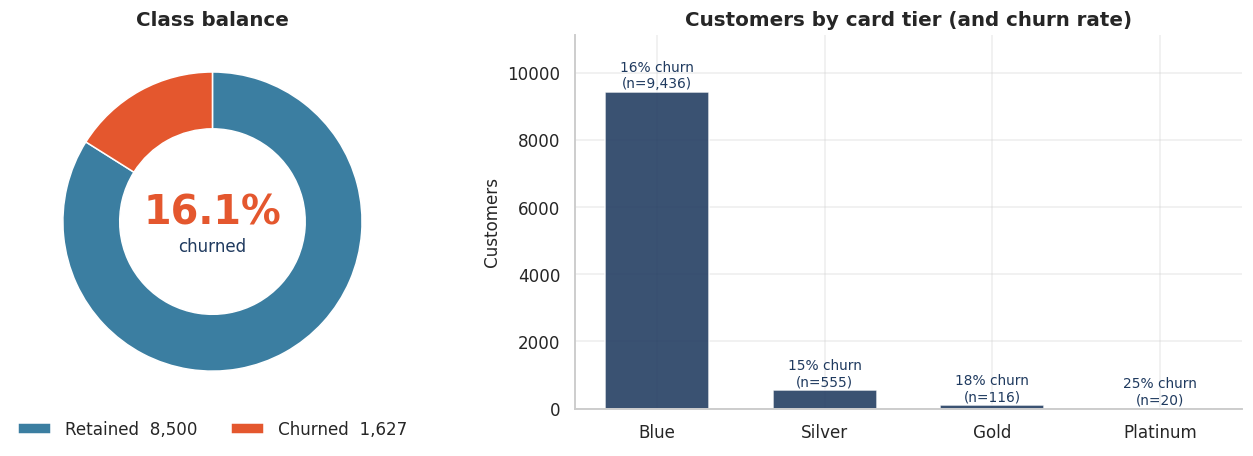

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.35]})

# (a) class balance as a donut
counts = df["Attrition_Flag"].value_counts().reindex(["Existing Customer", "Attrited Customer"])
axes[0].pie(counts, colors=[RETAINED, CHURNED], startangle=90, counterclock=False,
            wedgeprops={"width": 0.38, "edgecolor": "white"})
axes[0].text(0, 0.06, f"{BASE_RATE:.1%}", ha="center", va="center", fontsize=26, fontweight="bold", color=CHURNED)
axes[0].text(0, -0.2, "churned", ha="center", fontsize=11, color=NAVY)
axes[0].set_title("Class balance")
axes[0].legend([f"Retained  {counts.iloc[0]:,}", f"Churned  {counts.iloc[1]:,}"], loc="lower center",
               bbox_to_anchor=(0.5, -0.12), ncol=2)

# (b) customers by card tier, annotated with each tier's churn rate
tier = churn_summary(df, df["Card_Category"])
bars = axes[1].bar(tier.index.astype(str), tier["customers"], color=NAVY, alpha=0.88, width=0.62)
for b, (_, r) in zip(bars, tier.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 120,
                 f"{r.churn_rate:.0%} churn\n(n={int(r.customers):,})", ha="center", fontsize=9, color=NAVY)
axes[1].set_ylim(0, tier["customers"].max() * 1.18)
axes[1].set_title("Customers by card tier (and churn rate)")
axes[1].set_ylabel("Customers")
fig.tight_layout()
save_fig(fig, "01_class_balance_card_mix")

**What it shows.** 16.1% of customers churned. That is a mild imbalance, but it means *accuracy is a misleading metric* - a model that predicts "nobody leaves" would be 84% accurate and useless - so this notebook uses ranking metrics (AUC, KS, lift) throughout. The portfolio is 93.2% Blue cards; Silver (555), Gold (116) and Platinum (20) are too small for firm conclusions (Platinum's 25% churn rests on 20 customers).

**Figure 2 - where do the two groups differ?** Each panel overlays the distribution of one field for retained (blue) and churned (orange) customers, each normalised to its own group so the shapes are comparable. Look for places where the two outlines separate.

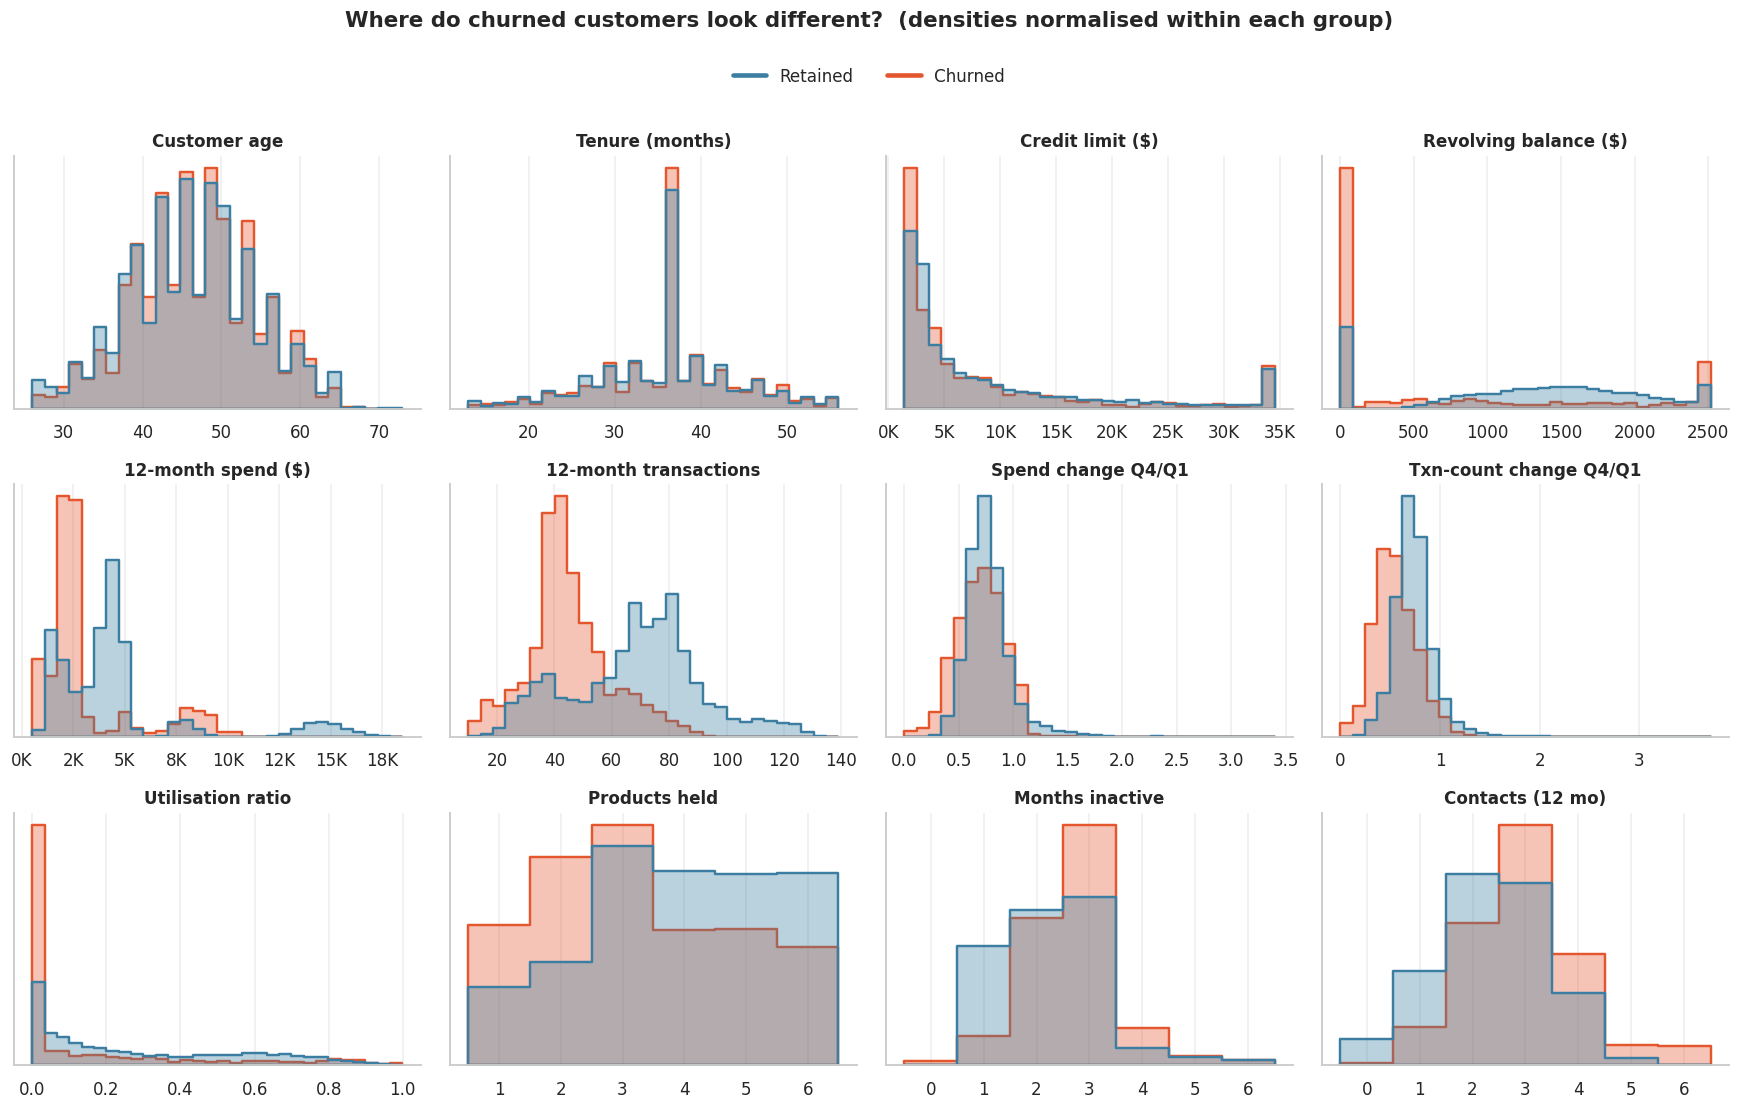

In [12]:
dist_cols = ["Customer_Age", "Months_on_book", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt", "Total_Trans_Ct",
             "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1", "Avg_Utilization_Ratio",
             "Total_Relationship_Count", "Months_Inactive_12_mon", "Contacts_Count_12_mon"]

fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, col in zip(axes.ravel(), dist_cols):
    discrete = df[col].nunique() <= 8
    bins = np.arange(df[col].min() - 0.5, df[col].max() + 1.5) if discrete else 30
    sns.histplot(data=df, x=col, hue="Attrition_Flag", palette=PALETTE, stat="density", common_norm=False,
                 element="step", bins=bins, alpha=0.35, linewidth=1.6, ax=ax, legend=False)
    ax.set_title(PRETTY[col], fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
    if df[col].max() > 5000:                                   # show $ columns as 5K, 10K ... so labels never collide
        ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v / 1000:.0f}K"))
handles = [plt.Line2D([0], [0], color=c, lw=3) for c in PALETTE.values()]
fig.legend(handles, ["Retained", "Churned"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02), fontsize=11)
fig.suptitle("Where do churned customers look different?  (densities normalised within each group)", y=1.06, fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_distributions_by_churn")

**What it shows**

- **Age and tenure overlap almost perfectly**: whoever you are and however long you have been a customer, you are no more likely to leave. Tenure has a tall spike at 36 months (24% of customers), hinting at a batch of customers acquired together.
- **Churners pile up at zero revolving balance and zero utilisation**, at roughly \$2K of annual spend, and at 35-50 transactions.
- **Spend and transactions are not bell-shaped**: they are multi-modal, with distinct clusters. Averages will mislead, which is why the questions below work with bins and rates instead.
- **Ceilings**: 5% of customers sit exactly at a revolving balance of \$2,517 and credit limits stop at \$34,516 - the data is capped.
- Churners hold **fewer products** and have **more months inactive and more bank contacts**.

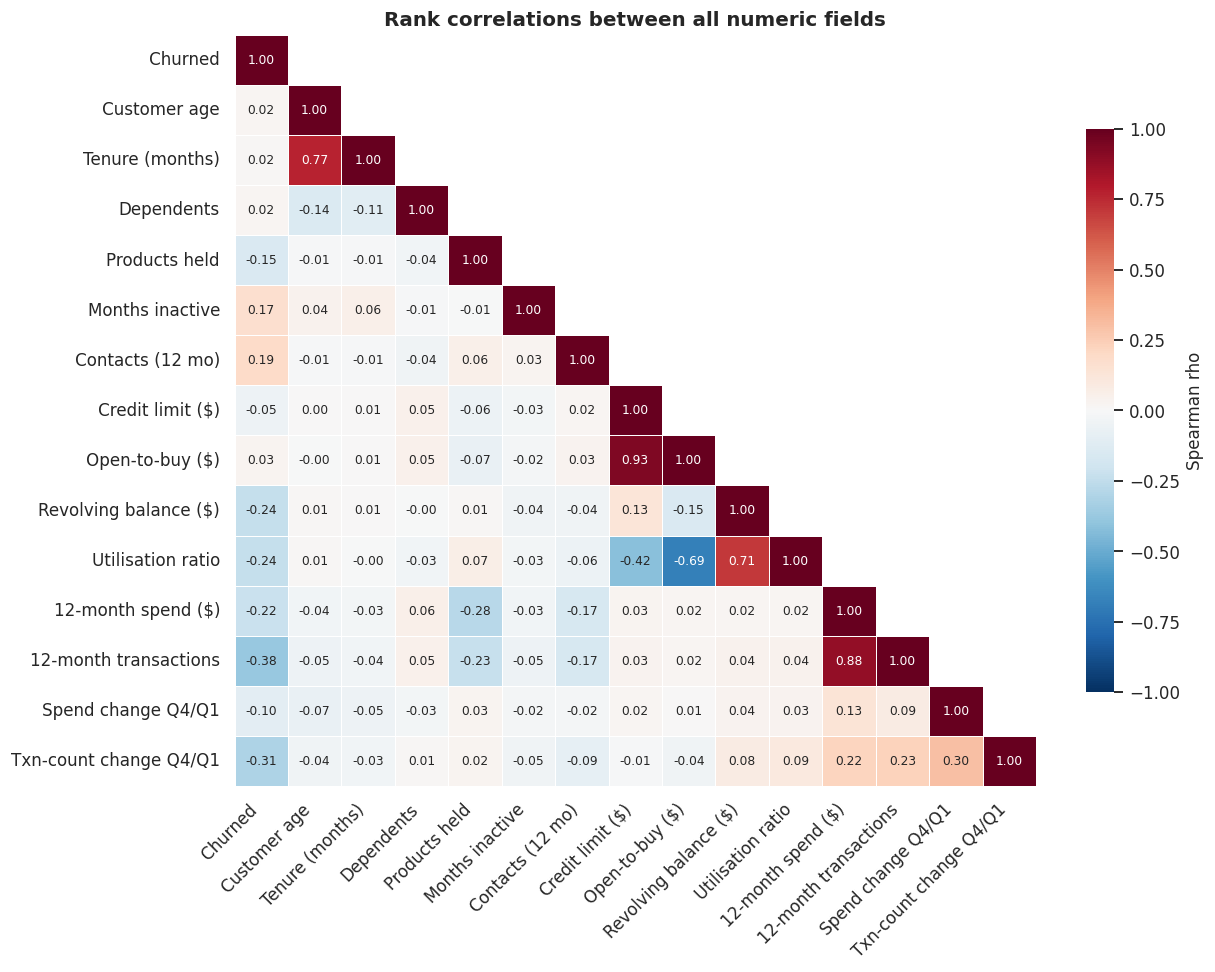

Total_Trans_Ct             -0.376
Total_Ct_Chng_Q4_Q1        -0.312
Total_Revolving_Bal        -0.241
Avg_Utilization_Ratio      -0.240
Total_Trans_Amt            -0.224
Total_Relationship_Count   -0.150
Total_Amt_Chng_Q4_Q1       -0.102
Credit_Limit               -0.051
Months_on_book              0.015
Customer_Age                0.018
Dependent_count             0.021
Avg_Open_To_Buy             0.028
Months_Inactive_12_mon      0.172
Contacts_Count_12_mon       0.189


In [13]:
corr_cols = ["churn", "Customer_Age", "Months_on_book", "Dependent_count", "Total_Relationship_Count",
             "Months_Inactive_12_mon", "Contacts_Count_12_mon", "Credit_Limit", "Avg_Open_To_Buy", "Total_Revolving_Bal",
             "Avg_Utilization_Ratio", "Total_Trans_Amt", "Total_Trans_Ct", "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1"]
corr = df[corr_cols].rank().corr()                         # Spearman = Pearson correlation of the ranks: robust to skew and outliers
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11.5, 9))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.75, "label": "Spearman rho"}, ax=ax)
ax.grid(False)
ax.set_xticklabels([PRETTY[c] for c in corr.columns], rotation=45, ha="right")
ax.set_yticklabels([PRETTY[c] for c in corr.index], rotation=0)
ax.set_title("Rank correlations between all numeric fields")
fig.tight_layout()
save_fig(fig, "03_correlation_heatmap")

print(corr["churn"].drop("churn").sort_values().round(3).to_string())

**What it shows.** Rank correlations with churn: transactions **-0.38**, Q4/Q1 transaction ratio **-0.31**, revolving balance and utilisation **-0.24**, spend **-0.22**, products held **-0.15**; contacts **+0.19** and months inactive **+0.17**. Age, tenure and dependents sit at about +0.02. The matrix also reveals redundant pairs worth treating as one: credit limit and open-to-buy (0.93), spend and transactions (0.88), age and tenure (0.77), utilisation and revolving balance (0.71).

**Caution.** A correlation only sees *straight-line* relationships. Question 1 shows how badly that can understate a signal.

**Figure 4 - give demographics a fair hearing.** For every category of every demographic and account-profile field, the churn rate with a 95% confidence interval. A dot is red only if its interval excludes the overall churn rate; wide intervals mean "too few customers to say".

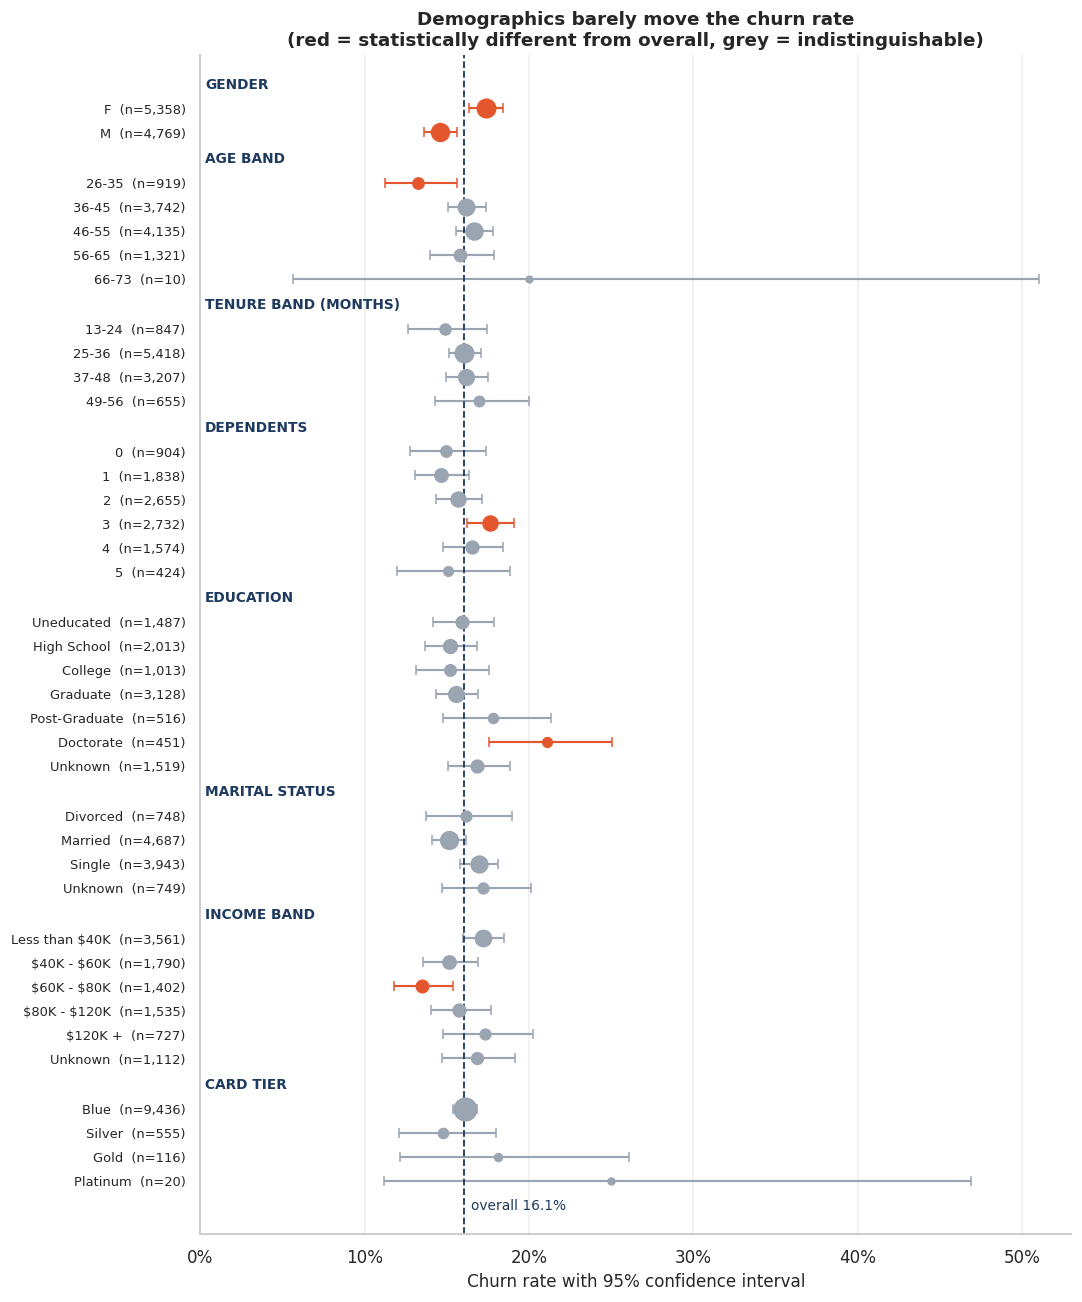

,group,level,customers,churn_rate,ci_low,ci_high
0,Gender,F,5358,0.174,0.164,0.184
1,Gender,M,4769,0.146,0.136,0.156
2,Age band,26-35,919,0.133,0.112,0.156
14,Dependents,3,2732,0.176,0.163,0.191
22,Education,Doctorate,451,0.211,0.176,0.251
30,Income band,$60K - $80K,1402,0.135,0.118,0.154


In [14]:
forest_vars = [("Gender", "Gender"), ("age_band", "Age band"), ("tenure_band", "Tenure band (months)"),
               ("Dependent_count", "Dependents"), ("Education_Level", "Education"), ("Marital_Status", "Marital status"),
               ("Income_Category", "Income band"), ("Card_Category", "Card tier")]
parts = []
for col, label in forest_vars:
    s = churn_summary(df, df[col]).reset_index().rename(columns={col: "level"})
    s["group"] = label
    s["level"] = s["level"].astype(str)
    parts.append(s)
forest = pd.concat(parts, ignore_index=True)
forest["differs"] = (forest["ci_low"] > BASE_RATE) | (forest["ci_high"] < BASE_RATE)

fig, ax = plt.subplots(figsize=(10, 12))
y, ticks, labels = 0, [], []
for grp, sub in forest.groupby("group", sort=False):
    y -= 1.1
    ax.text(0.003, y, grp.upper(), fontsize=9, fontweight="bold", color=NAVY, va="center")
    for _, r in sub.iterrows():
        y -= 1
        colr = CHURNED if r["differs"] else GREY
        ax.errorbar(r["churn_rate"], y, xerr=[[r["churn_rate"] - r["ci_low"]], [r["ci_high"] - r["churn_rate"]]],
                    fmt="o", color=colr, ecolor=colr, ms=4 + np.sqrt(r["customers"]) / 9, capsize=3, lw=1.4)
        ticks.append(y)
        labels.append(esc(f"{r['level']}  (n={int(r['customers']):,})"))
ax.axvline(BASE_RATE, color=NAVY, ls="--", lw=1.2)
ax.text(BASE_RATE + 0.004, y - 1.2, f"overall {BASE_RATE:.1%}", color=NAVY, fontsize=9)
ax.set_yticks(ticks)
ax.set_yticklabels(labels, fontsize=8.5)
ax.set_xlim(0, max(0.42, forest["ci_high"].max() + 0.02))
pct_axis(ax, "x")
ax.set_xlabel("Churn rate with 95% confidence interval")
ax.set_title("Demographics barely move the churn rate\n(red = statistically different from overall, grey = indistinguishable)", fontsize=12)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "04_demographics_forest_plot")

display(forest.loc[forest["differs"], ["group", "level", "customers", "churn_rate", "ci_low", "ci_high"]])

**What it shows.** Of 38 category levels, only six differ significantly from the overall 16.1%, and none by more than about 5 points: women 17.4% vs men 14.6%, ages 26-35 (13.3%), three dependents (17.6%), doctorates (21.1%, 451 customers) and the \$60K-\$80K income band (13.5%). With 38 tests at 95% confidence, about two "significant" results are expected by chance alone. **Tenure** is flat (14.9%-16.9% across bands): newer customers do not churn more (H4) - at least beyond the first year, which the data does not cover.

---
# Step 4 - Ask and answer questions about the data

Eleven questions, each with the same rhythm: **question -> method -> evidence -> answer**. Questions 1-8 diagnose the problem, 9-11 turn the diagnosis into something a retention team can use.

## Q1. Which fields separate churners from stayers - who customers *are*, or what they *do*?

**Method - Information Value (IV).** Borrowed from credit-risk scorecards: cut a variable into bins, compare the share of churners and of stayers falling in each bin (their *Weight of Evidence*, WoE = ln of the ratio), and sum the gaps. Rule of thumb: IV below 0.02 is useless, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong, above 0.5 very strong (and worth a second look). To know what "nothing" looks like, a column of **pure random noise** is scored the same way.

> **Function spotlight - `pd.crosstab`, `np.log`, `Series.rank().corr()`**
> `crosstab` counts how often each combination of two columns occurs (here: bin x churn). `np.log` is the natural logarithm, applied to a whole column at once. `rank()` replaces values by their rank, and the correlation of two rank columns is the *Spearman* correlation - whether two variables rise and fall together - which shows only *monotonic* relationships.

In [15]:
profile = ["Customer_Age", "Gender", "Dependent_count", "Education_Level", "Marital_Status", "Income_Category"]
account = ["Card_Category", "Months_on_book", "Credit_Limit", "Total_Relationship_Count"]
behaviour = ["Total_Trans_Ct", "Total_Trans_Amt", "Total_Revolving_Bal", "Total_Ct_Chng_Q4_Q1",
             "Avg_Utilization_Ratio", "Contacts_Count_12_mon", "Months_Inactive_12_mon", "Total_Amt_Chng_Q4_Q1"]
FAMILY_COLORS = {"Demographic profile": GREY, "Account & relationship": ACCENT, "Behaviour": CHURNED, "Benchmark": NAVY}

rows = []
for fam, cols_ in [("Demographic profile", profile), ("Account & relationship", account), ("Behaviour", behaviour)]:
    for c in cols_:
        _, iv = iv_table(df[c], df["churn"])
        rho = df[c].rank().corr(df["churn"].rank()) if pd.api.types.is_numeric_dtype(df[c]) else np.nan
        rows.append({"feature": PRETTY[c], "family": fam, "IV": iv, "abs_rho": abs(rho)})

# A column of pure random noise tells us what an IV of "nothing" looks like with 10 bins
noise = pd.Series(np.random.default_rng(SEED).normal(size=len(df)), index=df.index)
_, iv_noise = iv_table(noise, df["churn"])
rows.append({"feature": "Random noise (benchmark)", "family": "Benchmark", "IV": iv_noise,
             "abs_rho": abs(noise.rank().corr(df["churn"].rank()))})
iv_df = pd.DataFrame(rows).sort_values("IV", ascending=False).reset_index(drop=True)
display(iv_df.round(3))

,feature,family,IV,abs_rho
0,12-month transactions,Behaviour,1.908,0.376
1,12-month spend ($),Behaviour,1.890,0.224
2,Revolving balance ($),Behaviour,1.070,0.241
3,Txn-count change Q4/Q1,Behaviour,0.958,0.312
4,Utilisation ratio,Behaviour,0.614,0.240
5,Contacts (12 mo),Behaviour,0.498,0.189
6,Months inactive,Behaviour,0.370,0.172
7,Spend change Q4/Q1,Behaviour,0.242,0.102
8,Products held,Account & relationship,0.192,0.150
9,Credit limit ($),Account & relationship,0.121,0.051


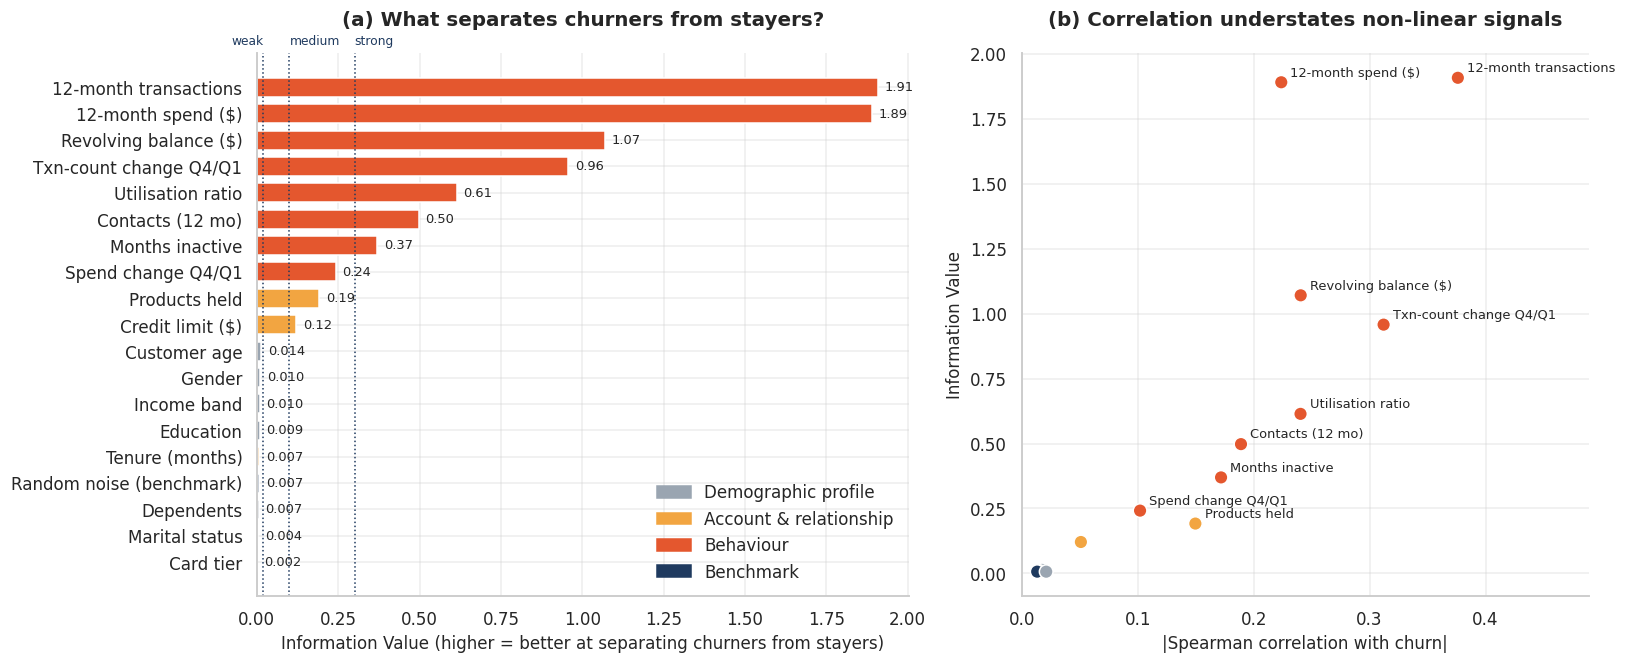

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.15, 1]})

# (a) IV ranking
plot_df = iv_df.sort_values("IV")
axes[0].barh(plot_df["feature"], plot_df["IV"], color=[FAMILY_COLORS[f] for f in plot_df["family"]], height=0.72)
for thr, lab, ha in [(0.02, "weak", "right"), (0.1, "medium", "left"), (0.3, "strong", "left")]:
    axes[0].axvline(thr, color=NAVY, ls=":", lw=1)
    axes[0].text(thr, 1.01, lab, transform=axes[0].get_xaxis_transform(), ha=ha, va="bottom", fontsize=8, color=NAVY)
for i, v in enumerate(plot_df["IV"]):
    axes[0].text(v + 0.02, i, f"{v:.3f}" if v < 0.05 else f"{v:.2f}", va="center", fontsize=8.5)
axes[0].set_xlabel("Information Value (higher = better at separating churners from stayers)")
axes[0].set_title("(a) What separates churners from stayers?", pad=18)
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()], FAMILY_COLORS.keys(),
               loc="lower right")

# (b) linear correlation vs IV
num_df = iv_df.dropna(subset=["abs_rho"])
axes[1].scatter(num_df["abs_rho"], num_df["IV"], s=80, c=[FAMILY_COLORS[f] for f in num_df["family"]],
                edgecolor="white", linewidth=1)
for _, r in num_df.iterrows():
    if r["IV"] > 0.15:
        axes[1].annotate(r["feature"], (r["abs_rho"], r["IV"]), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
axes[1].set_xlabel("|Spearman correlation with churn|")
axes[1].set_ylabel("Information Value")
axes[1].set_xlim(0, num_df["abs_rho"].max() * 1.3)
axes[1].set_title("(b) Correlation understates non-linear signals", pad=18)
fig.tight_layout()
save_fig(fig, "05_driver_ranking_iv")

**Answer.** Behaviour dominates and demographics are noise.

- Eight behavioural fields have IV between 0.24 and 1.91, led by **12-month transactions (1.91)**, **12-month spend (1.89)**, revolving balance (1.07) and the Q4/Q1 transaction ratio (0.96).
- Every demographic and profile field - age, gender, income, education, marital status, dependents, tenure, card tier - scores **0.002-0.014**, the same range as the random-noise benchmark (**0.007**). Products held (0.19) and credit limit (0.12) are the only account fields with real signal.
- **Panel (b)** is the methodological point: spend has an IV of 1.89 but a rank correlation of only 0.22. Churn is *non-linear* in spend and activity (next question), so a correlation matrix would have under-rated the strongest signal in the file.

**Verdict on H1: rejected.** *Caveat:* IV above 0.5 is unusually strong in real scorecards. Here it is partly because behaviour is measured over the same 12 months in which customers leave - see Limitations.

## Q2. Is churn simply "less activity means more churn"?

**Method.** Bin customers by transactions (5-wide bins) and by annual spend, compute the churn rate in each bin with a 95% confidence interval, and compare the average ticket size of churners and stayers. The grey bars in panel (a) show how many customers fall in each bin, so you can see which parts of the curve rest on a lot of data.

> **Function spotlight - `pd.cut`, `Axes.twinx`, `fill_between`**
> `pd.cut(x, edges)` assigns every value to a bin you define (here "35-40 transactions"). `twinx()` adds a second y-axis sharing the same x-axis so a rate and a count can sit on one chart. `fill_between` shades the confidence band around a line.

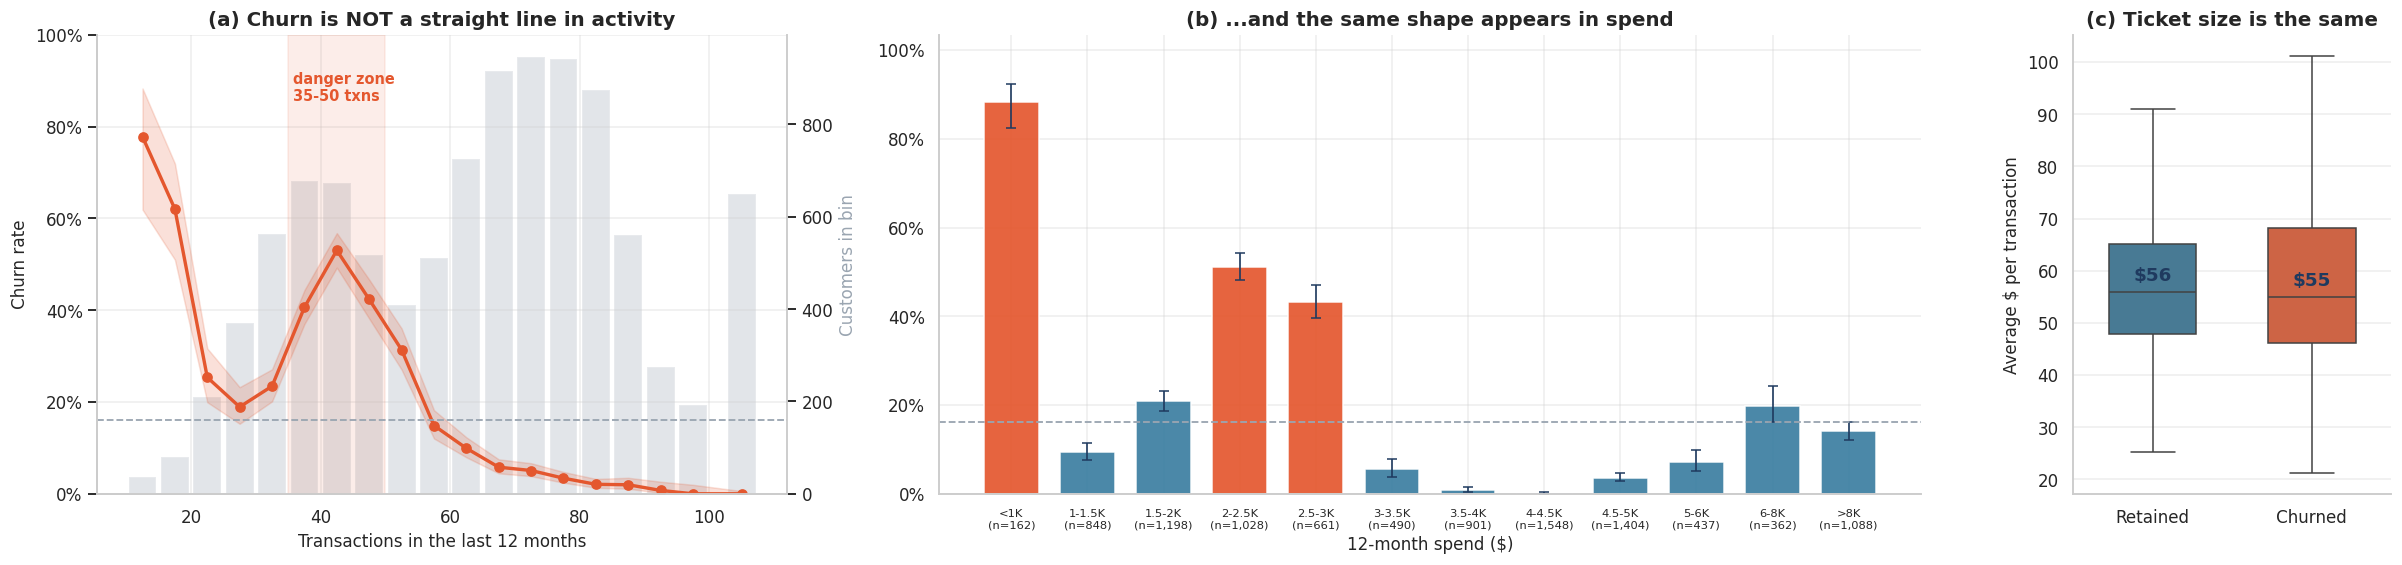

Danger zone (35-50 txns, contiguous run >= 40% churn): 1,867 customers (18.4% of base), churn 45.6%, holding 52.3% of all churners
Near-dormant (<=20 txns): 119 customers, churn 68.1%
Spend $3.5K-4.5K: 2,449 customers, 9 churners
Spend $2K-3K: 1,689 customers, churn 48.1%
Median ticket ($): {'Attrited Customer': 55.0, 'Existing Customer': 55.9}


,ct_bin,customers,churned,churn_rate
11,"(65, 70]",915,53,0.058
12,"(70, 75]",947,48,0.051
13,"(75, 80]",942,32,0.034
14,"(80, 85]",874,18,0.021
15,"(85, 90]",560,11,0.020
16,"(90, 95]",274,2,0.007
17,"(95, 100]",193,0,0.000
18,"(100, 140]",649,0,0.000


In [17]:
# ---- (a) churn vs number of transactions ----
ct_edges = list(range(10, 101, 5)) + [140]
df["ct_bin"] = pd.cut(df["Total_Trans_Ct"], ct_edges)
ct = churn_summary(df, df["ct_bin"]).reset_index()
ct["x"] = [iv.left + 2.5 for iv in ct["ct_bin"]]
ct.loc[ct.index[-1], "x"] = 105                                    # the last bin (100-140) is wider
# danger zone = the contiguous run of bins around the main churn peak (bins with >=300 customers) that stays >= 40%
peak = int(ct.loc[ct["customers"] >= 300, "churn_rate"].idxmax())
lo = hi = peak
while lo - 1 >= 0 and ct.loc[lo - 1, "churn_rate"] >= 0.40:
    lo -= 1
while hi + 1 < len(ct) and ct.loc[hi + 1, "churn_rate"] >= 0.40:
    hi += 1
d_lo, d_hi = ct.loc[lo, "ct_bin"].left, ct.loc[hi, "ct_bin"].right

# ---- (b) churn vs annual spend ----
amt_edges = [0, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000, 6000, 8000, 20000]
amt_labels = ["<1K", "1-1.5K", "1.5-2K", "2-2.5K", "2.5-3K", "3-3.5K", "3.5-4K", "4-4.5K", "4.5-5K", "5-6K", "6-8K", ">8K"]
df["amt_bin"] = pd.cut(df["Total_Trans_Amt"], amt_edges, labels=amt_labels)
amt = churn_summary(df, df["amt_bin"])

fig, axes = plt.subplots(1, 3, figsize=(22, 5.3), gridspec_kw={"width_ratios": [1.3, 1.85, 0.6]})

ax = axes[0]
ax2 = ax.twinx()
ax2.bar(ct["x"], ct["customers"], width=4.3, color=GREY, alpha=0.28)
ax2.set_ylabel("Customers in bin", color=GREY)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)
ax.axvspan(d_lo, d_hi, color=CHURNED, alpha=0.10)
ax.fill_between(ct["x"], ct["ci_low"], ct["ci_high"], color=CHURNED, alpha=0.18)
ax.plot(ct["x"], ct["churn_rate"], color=CHURNED, marker="o", lw=2.2)
ax.axhline(BASE_RATE, ls="--", color=GREY, lw=1.2)
ax.text(d_lo + 0.8, 0.92, f"danger zone\n{d_lo:.0f}-{d_hi:.0f} txns", color=CHURNED, fontsize=9.5, fontweight="bold", va="top")
pct_axis(ax)
ax.set_ylim(0, 1)
ax.set_xlabel("Transactions in the last 12 months")
ax.set_ylabel("Churn rate")
ax.set_title("(a) Churn is NOT a straight line in activity")

ax = axes[1]
bar_ci(ax, amt, labels=list(amt.index.astype(str)), thresh=0.30, fontsize=7.5)
ax.set_xlabel("12-month spend ($)")
ax.set_title("(b) ...and the same shape appears in spend")

ax = axes[2]
sns.boxplot(data=df, x="Attrition_Flag", y="avg_ticket", hue="Attrition_Flag", palette=PALETTE, showfliers=False,
            order=["Existing Customer", "Attrited Customer"], hue_order=["Existing Customer", "Attrited Customer"],
            legend=False, width=0.55, ax=ax)
med = df.groupby("Attrition_Flag")["avg_ticket"].median()
for i, lab in enumerate(["Existing Customer", "Attrited Customer"]):
    ax.text(i, med[lab] + 2.2, f"${med[lab]:.0f}", ha="center", fontweight="bold", color=NAVY)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Retained", "Churned"])
ax.set_xlabel("")
ax.set_ylabel("Average $ per transaction")
ax.set_title("(c) Ticket size is the same")
fig.tight_layout()
save_fig(fig, "06_engagement_curves")

in_zone = df["Total_Trans_Ct"] > d_lo
in_zone &= df["Total_Trans_Ct"] <= d_hi
dormant = df["Total_Trans_Ct"] <= 20
print(f"Danger zone ({d_lo:.0f}-{d_hi:.0f} txns, contiguous run >= 40% churn): {in_zone.sum():,} customers "
      f"({in_zone.mean():.1%} of base), churn {df.loc[in_zone, 'churn'].mean():.1%}, "
      f"holding {df.loc[in_zone, 'churn'].sum() / df['churn'].sum():.1%} of all churners")
print(f"Near-dormant (<=20 txns): {dormant.sum()} customers, churn {df.loc[dormant, 'churn'].mean():.1%}")
print(f"Spend $3.5K-4.5K: {df['Total_Trans_Amt'].between(3501, 4500).sum():,} customers, "
      f"{df.loc[df['Total_Trans_Amt'].between(3501, 4500), 'churn'].sum()} churners")
print(f"Spend $2K-3K: {df['Total_Trans_Amt'].between(2001, 3000).sum():,} customers, "
      f"churn {df.loc[df['Total_Trans_Amt'].between(2001, 3000), 'churn'].mean():.1%}")
print("Median ticket ($):", med.round(1).to_dict())
display(ct[["ct_bin", "customers", "churned", "churn_rate"]].tail(8))

**Answer.** No - the relationship is a **hump, not a slope**.

- **Danger zone: 35-50 transactions a year.** 1,867 customers (18.4% of the base) churn at **45.6%** and contain **52.3% of all churners**. Churn dips to 19-25% for customers at 20-35 transactions, then peaks again here.
- **Near-dormant customers (20 transactions or fewer)** churn at 68%, but there are only 119 of them. **Above 60 transactions churn collapses** (5.8% for 65-70 transactions) and **no customer above 95 transactions has churned** (0 of 842).
- **Spend shows the same shape.** Customers spending \$2-3K a year churn at **48.1%** (1,689 customers); those spending **\$3.5K-\$4.5K churn at 0.4%** - 9 churners among 2,449 customers. Customers under \$1K churn at 88%.
- **Panel (c): ticket size is identical** (median \$56 retained vs \$55 churned). Churners are not "smaller" customers per purchase; they simply use the card less often.

**So what.** The problem is *usage frequency*. Retention levers should target how often a customer reaches for the card (spend-based rewards, everyday-category cashback), not the price of each transaction. **Verdict on H2: partly confirmed - but non-linear.**

## Q3. Does a fall in activity between Q1 and Q4 foreshadow churn - and does it add information beyond how active the customer is?

**Method.** `Total_Ct_Chng_Q4_Q1` is the ratio of the Q4 transaction count to Q1 (1.0 = unchanged, 0.5 = halved). Panel (a) shows churn by ratio; panel (b) crosses it with total activity to see whether the two signals overlap. Cells with fewer than 30 customers are left blank.

> **Function spotlight - `sns.heatmap`, `pd.crosstab(..., values=, aggfunc="mean")`**
> Giving `crosstab` a `values` column and `aggfunc="mean"` averages that column in every cell - for a 0/1 churn flag, the mean *is* the churn rate. `sns.heatmap` paints the resulting table by colour.

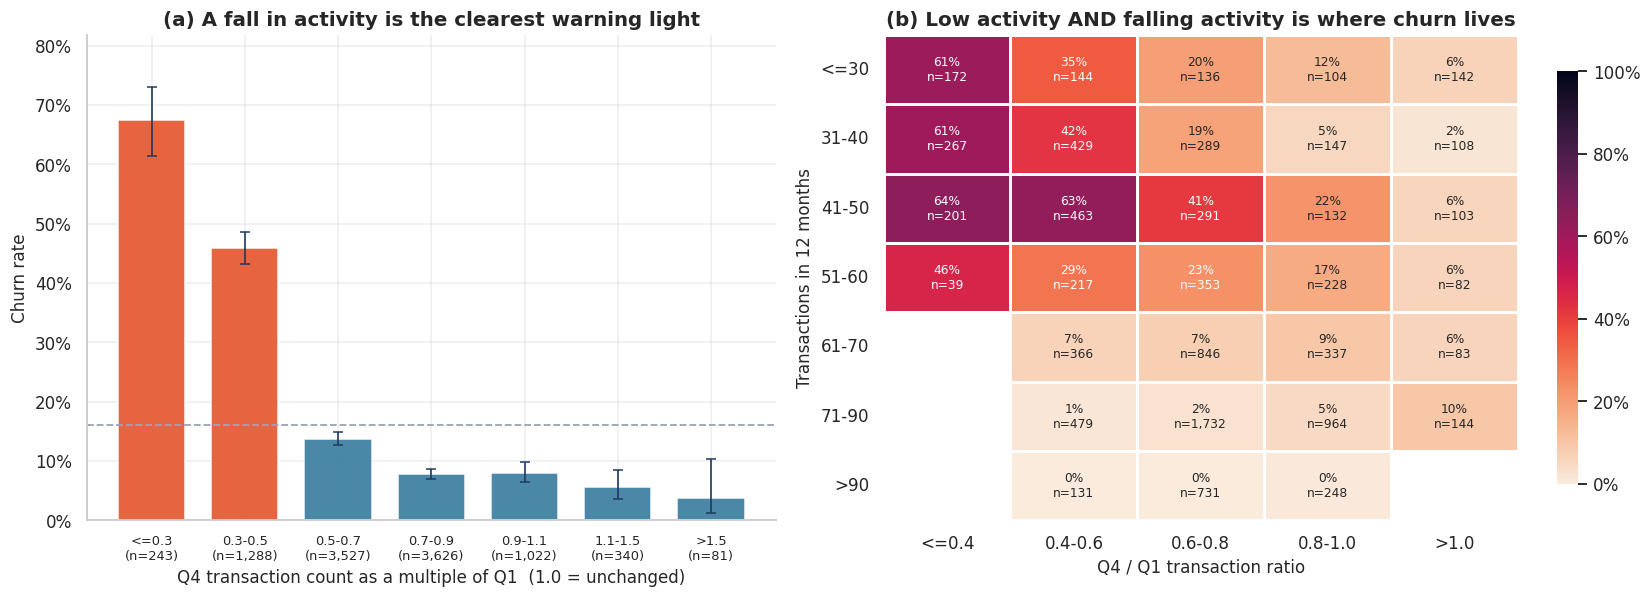

Customers with Q4/Q1 < 0.5: 1,370 (13.5% of base) -> churn 50.9% vs 10.6% for everyone else
These customers contain 42.8% of all churners
Correlation (Spearman) Trans_Ct vs Q4/Q1 ratio: 0.233


In [18]:
chg_edges = [0, 0.3, 0.5, 0.7, 0.9, 1.1, 1.5, 4]
chg_labels = ["<=0.3", "0.3-0.5", "0.5-0.7", "0.7-0.9", "0.9-1.1", "1.1-1.5", ">1.5"]
df["ctchg_bin"] = pd.cut(df["Total_Ct_Chng_Q4_Q1"], chg_edges, labels=chg_labels, include_lowest=True)
chg = churn_summary(df, df["ctchg_bin"])

ct_band_edges = [0, 30, 40, 50, 60, 70, 90, 150]
ct_band_labels = ["<=30", "31-40", "41-50", "51-60", "61-70", "71-90", ">90"]
df["ct_band"] = pd.cut(df["Total_Trans_Ct"], ct_band_edges, labels=ct_band_labels)
hm_edges = [0, 0.4, 0.6, 0.8, 1.0, 4]
hm_labels = ["<=0.4", "0.4-0.6", "0.6-0.8", "0.8-1.0", ">1.0"]
df["chg_band"] = pd.cut(df["Total_Ct_Chng_Q4_Q1"], hm_edges, labels=hm_labels, include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})
bar_ci(axes[0], chg, labels=chg_labels, thresh=0.30)
axes[0].set_xlabel("Q4 transaction count as a multiple of Q1  (1.0 = unchanged)")
axes[0].set_ylabel("Churn rate")
axes[0].set_title("(a) A fall in activity is the clearest warning light")
churn_heatmap(axes[1], df, "ct_band", "chg_band", xlabel="Q4 / Q1 transaction ratio", ylabel="Transactions in 12 months")
axes[1].set_title("(b) Low activity AND falling activity is where churn lives")
fig.tight_layout()
save_fig(fig, "07_activity_trend")

fade = df["Total_Ct_Chng_Q4_Q1"] < 0.5
print(f"Customers with Q4/Q1 < 0.5: {fade.sum():,} ({fade.mean():.1%} of base) -> churn {df.loc[fade, 'churn'].mean():.1%} "
      f"vs {df.loc[~fade, 'churn'].mean():.1%} for everyone else")
print(f"These customers contain {df.loc[fade, 'churn'].sum() / df['churn'].sum():.1%} of all churners")
print("Correlation (Spearman) Trans_Ct vs Q4/Q1 ratio:", round(df['Total_Trans_Ct'].rank().corr(df['Total_Ct_Chng_Q4_Q1'].rank()), 3))

**Answer.** Yes, strongly, and it carries information the activity level alone does not.

- Churn is **67.5%** when Q4 activity is at most 30% of Q1 and **45.9%** at 30-50%, but only 4-14% once the ratio passes 0.5.
- Customers with a ratio below 0.5 are **13.5% of the base, churn at 50.9% vs 10.6%** for everyone else, and contain **42.8% of all churners**.
- The ratio is only weakly related to total activity (rank correlation 0.23), so it is a *separate* warning light. Panel (b) shows the combination: customers with 41-50 transactions **and** a ratio under 0.6 churn at 63-64%, while customers above 70 transactions almost never leave, even when their activity dips (2% or less at ratios of 0.4-0.8).

**So what.** A Q4/Q1 activity ratio below 0.5-0.6 is an inexpensive trigger to monitor monthly. **Verdict on H3: confirmed.**

## Q4. Do bank contacts and inactivity signal trouble?

**Method.** Churn rate by number of contacts in the last 12 months and by months inactive, then a heat map of the two together. Bar whiskers are 95% confidence intervals.

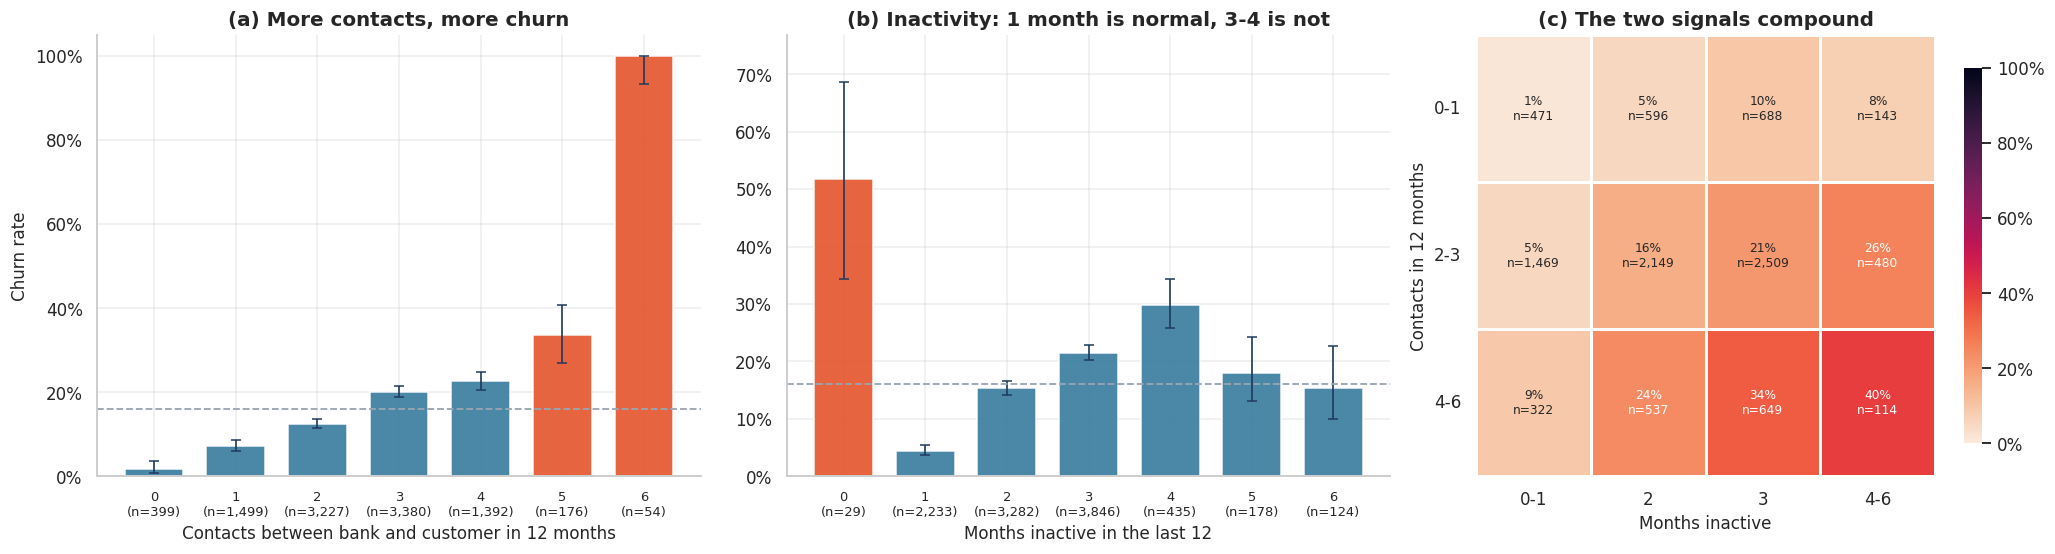

Customers with 6 contacts: 54 -> churn 100%
Customers with 0 contacts: 399 -> churn 1.8%
'Sleepers' (5-6 months inactive): 302 customers -> churn 16.9%


In [19]:
cont_s = churn_summary(df, df["Contacts_Count_12_mon"])
inact_s = churn_summary(df, df["Months_Inactive_12_mon"])
df["contacts_grp"] = pd.cut(df["Contacts_Count_12_mon"], [-1, 1, 3, 6], labels=["0-1", "2-3", "4-6"])
df["inactive_grp"] = pd.cut(df["Months_Inactive_12_mon"], [-1, 1, 2, 3, 6], labels=["0-1", "2", "3", "4-6"])

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1, 1, 0.95]})
bar_ci(axes[0], cont_s, labels=[str(i) for i in cont_s.index], thresh=0.30)
axes[0].set_xlabel("Contacts between bank and customer in 12 months")
axes[0].set_ylabel("Churn rate")
axes[0].set_title("(a) More contacts, more churn")
bar_ci(axes[1], inact_s, labels=[str(i) for i in inact_s.index], thresh=0.30)
axes[1].set_xlabel("Months inactive in the last 12")
axes[1].set_title("(b) Inactivity: 1 month is normal, 3-4 is not")
churn_heatmap(axes[2], df, "contacts_grp", "inactive_grp", xlabel="Months inactive", ylabel="Contacts in 12 months")
axes[2].set_title("(c) The two signals compound")
fig.tight_layout()
save_fig(fig, "08_service_friction")

six = df["Contacts_Count_12_mon"] == 6
print(f"Customers with 6 contacts: {six.sum()} -> churn {df.loc[six, 'churn'].mean():.0%}")
print(f"Customers with 0 contacts: {(df.Contacts_Count_12_mon == 0).sum()} -> churn {df.loc[df.Contacts_Count_12_mon == 0, 'churn'].mean():.1%}")
sleepers = df["Months_Inactive_12_mon"] >= 5
print(f"'Sleepers' (5-6 months inactive): {sleepers.sum()} customers -> churn {df.loc[sleepers, 'churn'].mean():.1%}")

**Answer.** Both are strong, and they compound.

- **Contacts rise in lockstep with churn**: 0 contacts 1.8% (399 customers), 1 contact 7.2%, 2 contacts 12.5%, 3 contacts 20.1%, 4 contacts 22.6%, 5 contacts 33.5%, and **6 contacts 100% (all 54 customers)**.
- **Inactivity is not a straight line either.** One inactive month is normal (**4.5%**, 2,233 customers); three to four months is the danger zone (**22.3%**, 4,281 customers). Customers with 5-6 inactive months churn *less* (16.9%, 302 customers) - they have gone quiet without leaving, a natural **win-back** group. (Zero months inactive shows 52%, but that is 29 customers with a very wide interval.)
- **Combined**: customers with 0-1 contacts and 0-1 inactive months churn at **1.3%** (471 customers); with 4+ contacts and 4+ inactive months, **40.4%** (114 customers).

**Caution.** The data does not say *who* initiated each contact. A rising contact count may be dissatisfied customers calling in, or the bank's retention team calling customers it already suspects. Either way it is a strong marker; it just may not be an *early* one. **Verdict on H6: confirmed, direction unknown.**

## Q5. Do customers with more products stay longer - or is that only because they are more active?

**Method.** Panel (a) shows churn by number of products held. Panel (b) is the *confounder check*: it repeats the comparison separately within three activity tiers. If more products still help within each tier, the effect cannot be explained by activity alone.

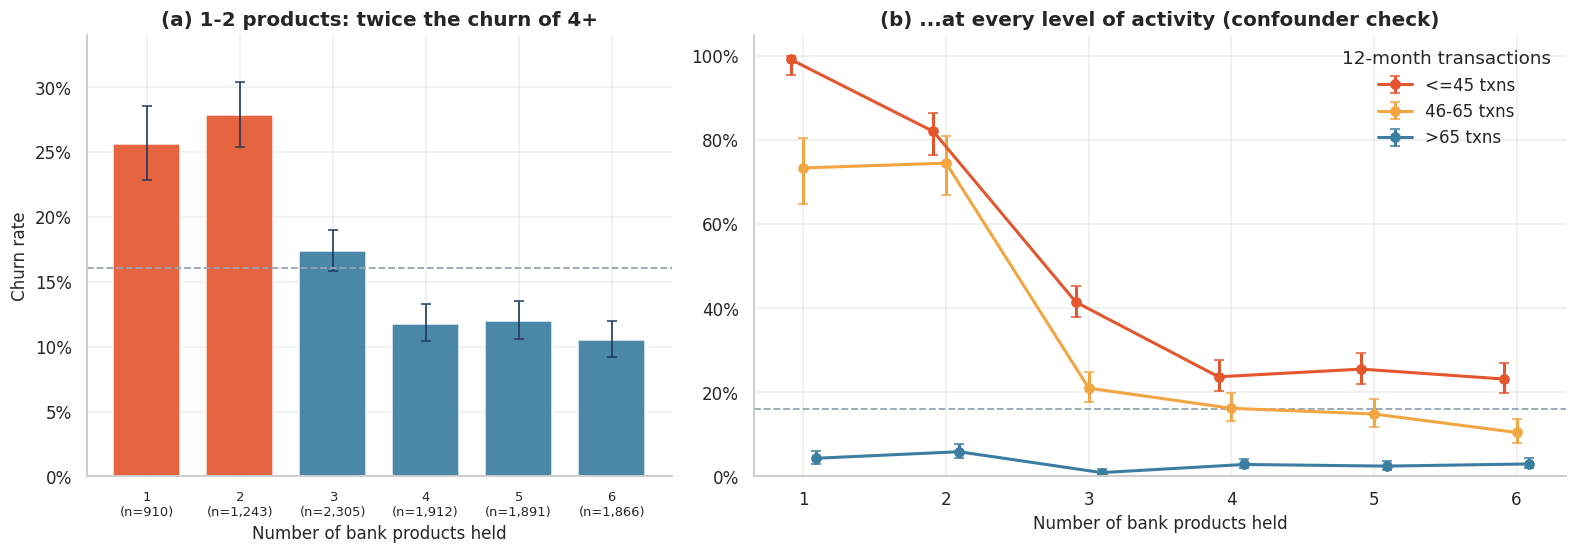

act_tier,<=45 txns,46-65 txns,>65 txns
Total_Relationship_Count,,,
1,99.1%,73.3%,4.3%
2,82.0%,74.5%,5.9%
3,41.4%,21.0%,0.9%
4,23.7%,16.2%,2.8%
5,25.5%,14.8%,2.4%
6,23.1%,10.4%,3.0%


In [20]:
overall = churn_summary(df, df["Total_Relationship_Count"])
tiered = churn_summary(df, [df["Total_Relationship_Count"], df["act_tier"]]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [0.9, 1.25]})
bar_ci(axes[0], overall, labels=[str(i) for i in overall.index], thresh=0.20)
axes[0].set_xlabel("Number of bank products held")
axes[0].set_ylabel("Churn rate")
axes[0].set_title("(a) 1-2 products: twice the churn of 4+")

tier_colors = {"<=45 txns": CHURNED, "46-65 txns": ACCENT, ">65 txns": RETAINED}
for i, (tier, colr) in enumerate(tier_colors.items()):
    s = tiered[tiered["act_tier"] == tier]
    off = (i - 1) * 0.09
    axes[1].errorbar(s["Total_Relationship_Count"] + off, s["churn_rate"],
                     yerr=[s["churn_rate"] - s["ci_low"], s["ci_high"] - s["churn_rate"]],
                     color=colr, marker="o", lw=2, capsize=3, label=tier)
axes[1].axhline(BASE_RATE, ls="--", color=GREY, lw=1.2)
pct_axis(axes[1])
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel("Number of bank products held")
axes[1].set_title("(b) ...at every level of activity (confounder check)")
axes[1].legend(title="12-month transactions", loc="upper right")
fig.tight_layout()
save_fig(fig, "09_relationship_depth")

pivot = tiered.pivot(index="Total_Relationship_Count", columns="act_tier", values="churn_rate")
display(pivot.style.format("{:.1%}"))

**Answer.** The effect is real and survives the check.

- **One or two products: 26.9% churn (2,153 customers). Four or more: 11.4% (5,669 customers)** - 2.4x lower.
- **Inside every activity tier** more products help. Among customers with 45 or fewer transactions, churn falls from **99.1% (one product, 117 customers)** and 82.0% (two) to 41.4% (three) and 23-26% (four to six). Among 46-65 transactions it falls from 73-75% (one to two products) to 21% (three) and 10-16% (four to six). Above 65 transactions churn is 1-6% whatever the product count.
- The biggest step is the move **from two to three products** in low and mid-activity tiers.

**Caution - association, not cause.** Customers who are happy may simply accumulate products. Whether *cross-selling* a third product reduces churn needs a controlled pilot. **Verdict on H5: confirmed as an association.**

## Q6. Women churn slightly more (17.4% vs 14.6%). Is that real, or an artefact of income?

**Method.** The gender-by-income cross-tab looks odd, so first inspect it, then compare men and women *like for like*: within the same income band (panel b) and within the same activity tier (panel c).

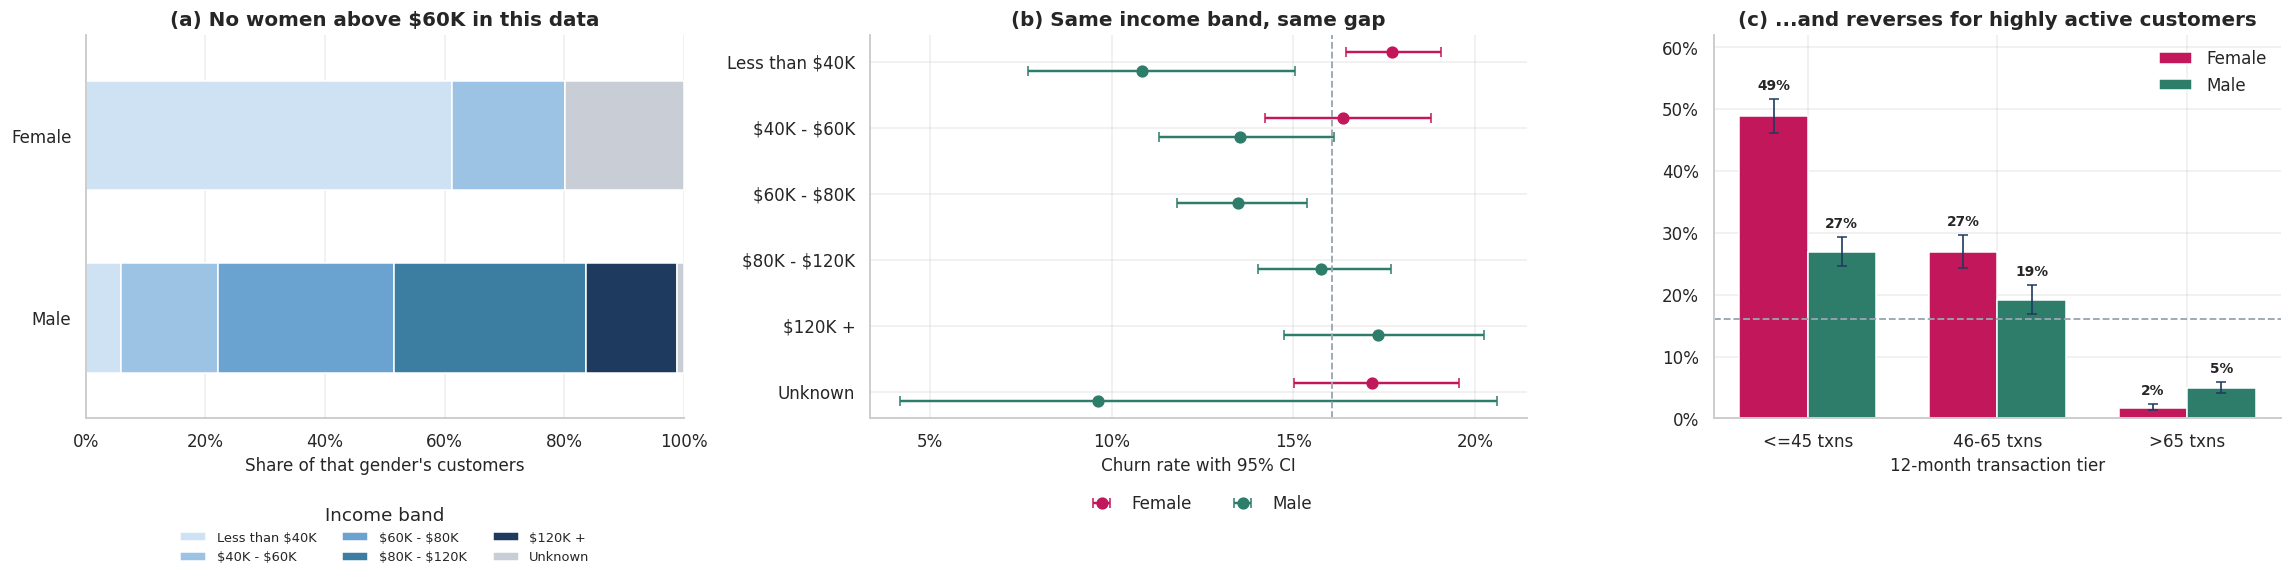

Churn rate by gender within activity tier:


act_tier,<=45 txns,46-65 txns,>65 txns
Gender,,,
F,48.9%,26.8%,1.7%
M,26.9%,19.1%,4.9%


Customers:


act_tier,<=45 txns,46-65 txns,>65 txns
Gender,,,
F,1209,1062,3087
M,1402,1100,2267


Average 12-month transactions by gender: {'F': 66.4, 'M': 63.2}


Gender,F,M
Income_Category,,
Less than $40K,17.7%,10.8%
$40K - $60K,16.4%,13.5%
$60K - $80K,-,13.5%
$80K - $120K,-,15.8%
$120K +,-,17.3%
Unknown,17.2%,9.6%


In [21]:
income_mix = pd.crosstab(df["Gender"], df["Income_Category"], normalize="index")
gi = churn_summary(df, [df["Income_Category"], df["Gender"]]).reset_index()
tg = churn_summary(df, [df["act_tier"], df["Gender"]]).reset_index()
gcol = {"F": "#C2185B", "M": "#2E7D6B"}
gname = {"F": "Female", "M": "Male"}

fig, axes = plt.subplots(1, 3, figsize=(21, 5.6), gridspec_kw={"width_ratios": [1, 1.1, 0.95]})

# (a) income mix by gender
income_colors = ["#CFE2F3", "#9CC3E4", "#6AA3D0", "#3B7EA1", "#1F3A5F", "#C9CED6"]
income_mix.loc[["M", "F"]].plot(kind="barh", stacked=True, color=income_colors, ax=axes[0], width=0.6, edgecolor="white")
axes[0].set_xlim(0, 1)
pct_axis(axes[0], "x")
axes[0].set_ylabel("")
axes[0].set_xlabel("Share of that gender's customers")
axes[0].set_title("(a) No women above $60K in this data")
h, _ = axes[0].get_legend_handles_labels()
axes[0].legend(h, [esc(c) for c in income_mix.columns], title="Income band", bbox_to_anchor=(0.5, -0.2),
               loc="upper center", ncol=3, fontsize=8.5)
axes[0].set_yticklabels(["Male", "Female"], rotation=0)

# (b) like-for-like inside each income band
for g, off in [("F", -0.14), ("M", 0.14)]:
    s = gi[gi["Gender"] == g].dropna(subset=["churn_rate"])
    ypos = [income_order.index(str(v)) + off for v in s["Income_Category"]]
    axes[1].errorbar(s["churn_rate"], ypos, xerr=[s["churn_rate"] - s["ci_low"], s["ci_high"] - s["churn_rate"]],
                     fmt="o", color=gcol[g], capsize=3, lw=1.6, ms=7, label=gname[g])
axes[1].set_yticks(range(len(income_order)))
axes[1].set_yticklabels([esc(c) for c in income_order])
axes[1].invert_yaxis()
axes[1].axvline(BASE_RATE, color=GREY, ls="--", lw=1.2)
axes[1].xaxis.set_major_locator(mtick.MultipleLocator(0.05))
pct_axis(axes[1], "x")
axes[1].set_xlabel("Churn rate with 95% CI")
axes[1].set_title("(b) Same income band, same gap")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

# (c) the gap depends entirely on activity level
tiers_ = ["<=45 txns", "46-65 txns", ">65 txns"]
w = 0.36
for j, g in enumerate(["F", "M"]):
    s = tg[tg["Gender"] == g].set_index("act_tier").reindex(tiers_)
    xs = np.arange(3) + (j - 0.5) * w
    axes[2].bar(xs, s["churn_rate"], width=w, color=gcol[g], label=gname[g])
    axes[2].errorbar(xs, s["churn_rate"], yerr=[s["churn_rate"] - s["ci_low"], s["ci_high"] - s["churn_rate"]],
                     fmt="none", ecolor=NAVY, capsize=3, lw=1.1)
    for x_, r_, hi_ in zip(xs, s["churn_rate"], s["ci_high"]):
        axes[2].text(x_, hi_ + 0.015, f"{r_:.0%}", ha="center", fontsize=9, fontweight="bold")
axes[2].set_xticks(range(3))
axes[2].set_xticklabels(tiers_)
axes[2].axhline(BASE_RATE, ls="--", color=GREY, lw=1.2)
pct_axis(axes[2])
axes[2].set_ylim(0, 0.62)
axes[2].set_xlabel("12-month transaction tier")
axes[2].set_title("(c) ...and reverses for highly active customers")
axes[2].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "10_gender_income_check")

gap = pd.crosstab(df["Gender"], df["act_tier"], values=df["churn"], aggfunc="mean")
gap_n = pd.crosstab(df["Gender"], df["act_tier"])
print("Churn rate by gender within activity tier:")
display(gap.style.format("{:.1%}"))
print("Customers:")
display(gap_n)
print("Average 12-month transactions by gender:", df.groupby("Gender")["Total_Trans_Ct"].mean().round(1).to_dict())
display(gi.pivot(index="Income_Category", columns="Gender", values="churn_rate").style.format("{:.1%}", na_rep="-"))

**Answer.** It is not an income artefact, and the overall gap hides something more interesting.

- **The income data is lopsided**: 61% of women are in the under-\$40K band and **none** appear above \$60K, while only 6% of men are under \$40K. Income and gender are tangled together in this file, so an overall gender comparison is confounded.
- **Within the same income band the gap persists**: under \$40K, women 17.7% vs men 10.8% (men: only 277 customers, wide interval); \$40K-\$60K, 16.4% vs 13.5%.
- **The gap depends on activity.** Among customers with 45 or fewer transactions, **women churn at 48.9% vs 26.9% for men** (1,209 and 1,402 customers); at 46-65 transactions, 26.8% vs 19.1%; **above 65 transactions it reverses: 1.7% vs 4.9%**. Women are over-represented in the high-activity tier (58% of women vs 48% of men), which dilutes their overall churn rate.

**So what.** Gender is a poor targeting variable (IV 0.010), but the pattern suggests women who disengage leave much more readily than men who disengage - worth investigating in service and product design. Given the unusually clean income pattern, check whether it also appears in production data. **Verdict on H8: rejected - the gap is not about income, and it reverses at high activity.**

## Q7. Do revolving balances and utilisation reveal who is safe - and who has already decided?

**Method.** Churn by fine bands of revolving balance (panel a), then zero-utilisation customers compared with revolvers inside each activity tier (panel b).

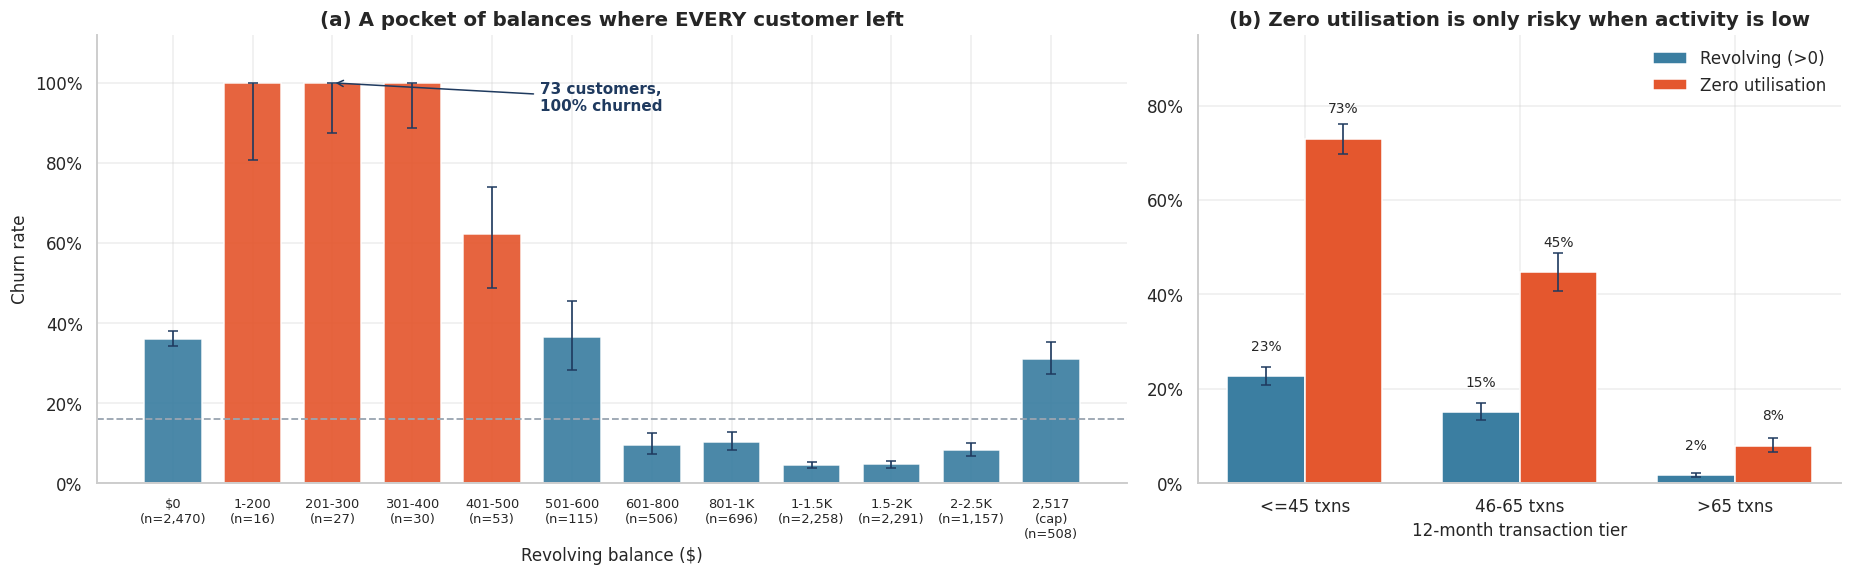

Pocket A (revolving balance $1-$400): 73 customers, churn 100%
Pocket B (6 contacts in 12 months):      54 customers, churn 100%
Overlap of the two pockets: 2 | together they hold 125 churners = 7.7% of all churners
Share of customers at the 2,517 balance cap: 5.0%


In [22]:
# (the smallest positive balance in the data is $132, so there is no 1-100 bin)
rb_edges = [-1, 0, 200, 300, 400, 500, 600, 800, 1000, 1500, 2000, 2516, 2600]
rb_labels = ["$0", "1-200", "201-300", "301-400", "401-500", "501-600", "601-800", "801-1K", "1-1.5K",
             "1.5-2K", "2-2.5K", "2,517\n(cap)"]
df["rb_bin"] = pd.cut(df["Total_Revolving_Bal"], rb_edges, labels=rb_labels)
rb = churn_summary(df, df["rb_bin"])
assert len(rb) == len(rb_labels), "every bin must be non-empty so labels line up with bars"

df["util_flag"] = np.where(df["Avg_Utilization_Ratio"] == 0, "Zero utilisation", "Revolving (>0)")
ut = churn_summary(df, [df["act_tier"], df["util_flag"]]).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.4), gridspec_kw={"width_ratios": [1.6, 1]})
colors = [CHURNED if v >= 0.5 else RETAINED for v in rb["churn_rate"]]
bar_ci(axes[0], rb, labels=rb_labels, color=colors)
axes[0].set_xlabel("Revolving balance ($)")
axes[0].set_ylabel("Churn rate")
axes[0].set_title("(a) A pocket of balances where EVERY customer left")
pocket_mask = (df["Total_Revolving_Bal"] > 0) & (df["Total_Revolving_Bal"] <= 400)
axes[0].annotate(f"{pocket_mask.sum()} customers,\n{df.loc[pocket_mask, 'churn'].mean():.0%} churned",
                 xy=(2, 1.0), xytext=(4.6, 0.93), arrowprops={"arrowstyle": "->", "color": NAVY}, fontsize=10,
                 fontweight="bold", color=NAVY)
axes[0].set_ylim(0, 1.12)

w = 0.36
tiers = list(ut["act_tier"].cat.categories) if hasattr(ut["act_tier"], "cat") else sorted(ut["act_tier"].unique())
for j, (flag, colr) in enumerate([("Revolving (>0)", RETAINED), ("Zero utilisation", CHURNED)]):
    s = ut[ut["util_flag"] == flag].set_index("act_tier").reindex(tiers)
    xs = np.arange(len(tiers)) + (j - 0.5) * w
    axes[1].bar(xs, s["churn_rate"], width=w, color=colr, label=flag)
    axes[1].errorbar(xs, s["churn_rate"], yerr=[s["churn_rate"] - s["ci_low"], s["ci_high"] - s["churn_rate"]],
                     fmt="none", ecolor=NAVY, capsize=3, lw=1.1)
    for x_, r_ in zip(xs, s["churn_rate"]):
        axes[1].text(x_, r_ + 0.055, f"{r_:.0%}", ha="center", fontsize=9)
axes[1].set_xticks(range(len(tiers)))
axes[1].set_xticklabels(tiers)
pct_axis(axes[1])
axes[1].set_ylim(0, 0.95)
axes[1].set_xlabel("12-month transaction tier")
axes[1].set_title("(b) Zero utilisation is only risky when activity is low")
axes[1].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "11_balance_pockets_utilisation")

six = df["Contacts_Count_12_mon"] == 6
pockets = pocket_mask | six
print(f"Pocket A (revolving balance $1-$400): {pocket_mask.sum()} customers, churn {df.loc[pocket_mask, 'churn'].mean():.0%}")
print(f"Pocket B (6 contacts in 12 months):      {six.sum()} customers, churn {df.loc[six, 'churn'].mean():.0%}")
print(f"Overlap of the two pockets: {(pocket_mask & six).sum()} | together they hold {df.loc[pockets, 'churn'].sum()} churners "
      f"= {df.loc[pockets, 'churn'].sum() / df['churn'].sum():.1%} of all churners")
print(f"Share of customers at the 2,517 balance cap: {(df.Total_Revolving_Bal == 2517).mean():.1%}")

**Answer.** Two different things are hiding here.

- **Zero utilisation is only dangerous when activity is low.** Overall, the 24.4% of customers with no revolving balance churn at 36.2% vs 9.6% for revolvers. But at 45 or fewer transactions the gap is **73% vs 23%**, and above 65 transactions it is just **8% vs 2%**. A customer who pays in full every month *and* uses the card constantly is a healthy "transactor", not a risk.
- **A pocket where everyone leaves.** All **73 customers with a revolving balance of \$1-\$400 churned (100%)**, and churn then falls smoothly: 62% for \$401-500, about 36% for \$501-600, and about 10% for \$601-\$1,000. The same happens with **six bank contacts: all 54 customers churned**. The two pockets barely overlap (2 customers) but together hold **125 churners = 7.7% of all churners**.

**Interpretation.** A small residual balance is exactly what an account looks like while a leaving customer pays it down - so this pocket is probably a *consequence* of the decision to leave, not a cause or an early warning. Treat such accounts as "already lost" (save desk), not as signals for proactive targeting. Q10 shows how much a scorecard flatters itself when it includes them. (5% of customers sit at the \$2,517 balance cap, with 31% churn - another reminder the data is capped.)

## Q8. What is churn really costing - and are the high-value customers the ones leaving?

**Method.** Compare the share of customers, credit limit, spend and revolving balance held by churned customers. The file has no revenue column, so revenue is *illustrated* as `interchange rate x spend + yield x revolving balance` using the assumptions at the top of the notebook (1.5% and 15%) - and, to avoid hanging conclusions on those guesses, tested across a grid of alternative assumptions. Then split customers into spend deciles to see where the lost spend sits.

> **Function spotlight - `pd.qcut`, `groupby().agg()` with named outputs**
> `qcut` splits customers into equal-sized groups (deciles: 10% each). `agg(name=("column", "function"))` computes several labelled summaries per group in one pass.

Share of ILLUSTRATIVE revenue held by churned customers under different assumptions:


,yield 10%,yield 15%,yield 20%,yield 25%
interchange 1.0%,9.8%,9.7%,9.6%,9.6%
interchange 1.5%,10.0%,9.8%,9.7%,9.7%
interchange 2.0%,10.2%,10.0%,9.8%,9.8%
interchange 2.5%,10.3%,10.1%,9.9%,9.8%


Bounds: 9.6% - 10.3%   (mathematically always between the spend share 11.3% and the revolving-balance share 9.3%)


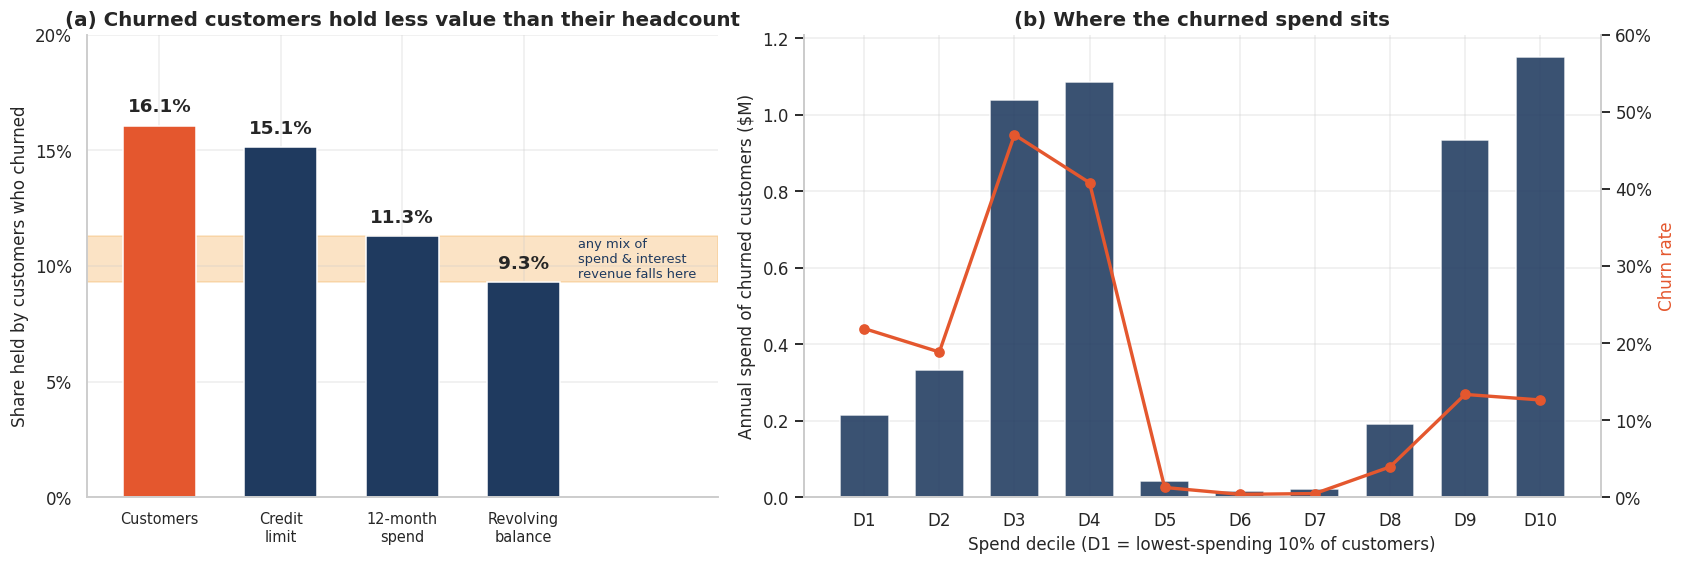

,customers,churn_rate,spend_at_risk,mean_spend,share_of_spend_at_risk
spend_decile,,,,,
D1,1014,0.219,214966,"1,227.844",0.043
D2,1013,0.189,334017,"1,707.431",0.066
D3,1012,0.470,1038908,"2,158.530",0.206
D4,1012,0.408,1086425,"2,713.824",0.216
D5,1013,0.013,43884,"3,597.293",0.009
D6,1014,0.004,15831,"4,096.096",0.003
D7,1012,0.005,22478,"4,422.419",0.004
D8,1013,0.039,191644,"4,742.315",0.038
D9,1011,0.134,935343,"6,228.122",0.186


Average 12-month spend  - retained: $4,655 | churned: $3,095
Average revolving balance - retained: $1,257 | churned: $673
Illustrative annual revenue per customer - retained: $258 | churned: $147
Illustrative revenue share held by churned customers (default assumptions): 9.8%


In [23]:
def churned_share(col):
    return (df[col] * df["churn"]).sum() / df[col].sum()

shares = pd.Series({
    "Customers": df["churn"].mean(),
    "Credit limit": churned_share("Credit_Limit"),
    "12-month spend": churned_share("Total_Trans_Amt"),
    "Revolving balance": churned_share("Total_Revolving_Bal"),
})
rev_share = churned_share("rev_est")

# Sensitivity: how does the churned share of revenue move with the assumed revenue mix?
grid = pd.DataFrame(
    {f"yield {y:.0%}": [((i * df["Total_Trans_Amt"] + y * df["Total_Revolving_Bal"]) * df["churn"]).sum() /
                       (i * df["Total_Trans_Amt"] + y * df["Total_Revolving_Bal"]).sum()
                       for i in (0.01, 0.015, 0.02, 0.025)] for y in (0.10, 0.15, 0.20, 0.25)},
    index=[f"interchange {i:.1%}" for i in (0.01, 0.015, 0.02, 0.025)])
print("Share of ILLUSTRATIVE revenue held by churned customers under different assumptions:")
display(grid.style.format("{:.1%}"))
print(f"Bounds: {grid.values.min():.1%} - {grid.values.max():.1%}   (mathematically always between the spend share "
      f"{shares['12-month spend']:.1%} and the revolving-balance share {shares['Revolving balance']:.1%})")

df["spend_decile"] = pd.qcut(df["Total_Trans_Amt"], 10, labels=[f"D{i}" for i in range(1, 11)])
dec = (df.assign(spend_at_risk=df["Total_Trans_Amt"] * df["churn"])
         .groupby("spend_decile", observed=True)
         .agg(customers=("churn", "size"), churn_rate=("churn", "mean"), spend_at_risk=("spend_at_risk", "sum"),
              mean_spend=("Total_Trans_Amt", "mean")))
dec["share_of_spend_at_risk"] = dec["spend_at_risk"] / dec["spend_at_risk"].sum()

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.3), gridspec_kw={"width_ratios": [0.95, 1.2]})
ax = axes[0]
ax.axhspan(shares["Revolving balance"], shares["12-month spend"], color=ACCENT, alpha=0.30, zorder=0)
ax.bar(range(4), shares.values, color=[CHURNED, NAVY, NAVY, NAVY], width=0.6, zorder=2)
ax.set_xticks(range(4))
ax.set_xticklabels(["Customers", "Credit\nlimit", "12-month\nspend", "Revolving\nbalance"])
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05))
for i, v in enumerate(shares.values):
    ax.text(i, v + 0.006, f"{v:.1%}", ha="center", fontweight="bold")
ax.text(3.45, (shares["Revolving balance"] + shares["12-month spend"]) / 2, "any mix of\nspend & interest\nrevenue falls here",
        fontsize=8.5, va="center", ha="left", color=NAVY)
pct_axis(ax)
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(0, 0.2)
ax.set_title("(a) Churned customers hold less value than their headcount")
ax.set_ylabel("Share held by customers who churned")
ax.tick_params(axis="x", labelsize=9.5)

ax = axes[1]
ax.bar(dec.index, dec["spend_at_risk"] / 1e6, color=NAVY, alpha=0.88, width=0.65)
ax.set_ylabel("Annual spend of churned customers ($M)")
ax.set_xlabel("Spend decile (D1 = lowest-spending 10% of customers)")
ax2 = ax.twinx()
ax2.plot(dec.index, dec["churn_rate"], color=CHURNED, marker="o", lw=2.2)
ax2.set_ylim(0, 0.6)
pct_axis(ax2)
ax2.set_ylabel("Churn rate", color=CHURNED)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title("(b) Where the churned spend sits")
fig.tight_layout()
save_fig(fig, "12_value_at_stake")

display(dec.round(3))
print("Average 12-month spend  - retained: ${:,.0f} | churned: ${:,.0f}".format(
    df.loc[df.churn == 0, "Total_Trans_Amt"].mean(), df.loc[df.churn == 1, "Total_Trans_Amt"].mean()))
print("Average revolving balance - retained: ${:,.0f} | churned: ${:,.0f}".format(
    df.loc[df.churn == 0, "Total_Revolving_Bal"].mean(), df.loc[df.churn == 1, "Total_Revolving_Bal"].mean()))
print("Illustrative annual revenue per customer - retained: ${:,.0f} | churned: ${:,.0f}".format(
    df.loc[df.churn == 0, "rev_est"].mean(), df.loc[df.churn == 1, "rev_est"].mean()))
print(f"Illustrative revenue share held by churned customers (default assumptions): {rev_share:.1%}")

**Answer.** Churn costs less than the headcount suggests - with one important exception.

- Churned customers are **16.1% of customers** but hold **15.1% of credit limit, 11.3% of spend and 9.3% of revolving balances**. Because revenue is a mix of spend-driven and balance-driven income, the churned share of revenue is *mathematically* between 9.3% and 11.3% whatever the mix - and **9.6%-10.3%** across the whole assumption grid (9.8% by default).
- The average churner generates about **57% of the revenue of a retained customer** (about \$147 vs \$258 a year under the illustrative assumptions): spend \$3,095 vs \$4,655, revolving balance \$673 vs \$1,257.
- **Panel (b): the churned spend sits in two places.** Deciles D3-D4 (customers spending about \$1.9-\$3.2K, churn **47% and 41%**) hold 42.2% of churned spend. But the **top two deciles (D9-D10) still churn at 13% and hold 41.5%** of churned spend, because each of these customers spends so much (D10 averages \$13,150).

**So what.** Headcount churn overstates the revenue at risk in the middle of the portfolio, and it *understates* the risk at the top. **Verdict on H7: rejected overall, but true for a high-spender pocket.**

## Q9. Can customers be grouped into a few personas an account manager would recognise - and where do the churners concentrate?

**Method.** Three signals that survived the earlier questions *and* are not post-decision symptoms: how **active** the customer is (65 or fewer transactions a year), whether activity is **fading** (Q4/Q1 ratio below 0.6) and how **deep** the relationship is (two or fewer products). Priority-ordered rules put every customer in exactly one persona:

| Persona | Rule |
|---|---|
| High-activity core | more than 65 transactions a year |
| Steady light users | 65 or fewer transactions, 3+ products, activity stable |
| Cooling regulars | 65 or fewer transactions, 3+ products, activity fading |
| Single-product drifters | 65 or fewer transactions, 1-2 products, activity stable |
| Exit-bound | 65 or fewer transactions, 1-2 products, activity fading |

> **Function spotlight - `np.select`**
> `np.select([cond1, cond2, ...], [label1, label2, ...], default=...)` assigns the label of the *first* condition that is true for each row - a vectorised version of an if / elif / else chain.

*Note: these cut-offs were chosen by eye from the curves above, using all customers, so persona churn rates are descriptive. The train/test table shows they are stable; the scorecard in Q10 is the properly held-out test.*

In [24]:
PERSONA_ORDER = ["High-activity core", "Steady light users", "Cooling regulars", "Single-product drifters", "Exit-bound"]

def assign_persona(d):
    """Priority-ordered rules: every customer lands in exactly one persona."""
    light = d["Total_Trans_Ct"] <= 65                    # <= 65 transactions a year
    fading = d["Total_Ct_Chng_Q4_Q1"] < 0.6              # Q4 activity below 60% of Q1
    thin = d["Total_Relationship_Count"] <= 2            # holds at most two products
    return np.select(
        [~light, light & thin & fading, light & thin & ~fading, light & ~thin & fading],
        ["High-activity core", "Exit-bound", "Single-product drifters", "Cooling regulars"],
        default="Steady light users")

df["persona"] = pd.Categorical(assign_persona(df), categories=PERSONA_ORDER, ordered=True)

persona = churn_summary(df, df["persona"])
persona["share of customers"] = persona["customers"] / len(df)
persona["share of churners"] = persona["churned"] / df["churn"].sum()
sar = df.assign(sar=df["Total_Trans_Amt"] * df["churn"]).groupby("persona", observed=True)["sar"].sum()
persona["spend at risk ($)"] = sar
persona["share of spend at risk"] = sar / sar.sum()
persona["avg 12-mo spend ($)"] = df.groupby("persona", observed=True)["Total_Trans_Amt"].mean()
display(persona.drop(columns=["ci_low", "ci_high"]).round(3))

stability = (df.groupby(["persona", "is_train"], observed=True)["churn"].mean().unstack()
               .rename(columns={True: "churn (train)", False: "churn (test)"}))
display(stability.style.format("{:.1%}"))

,customers,churned,churn_rate,share of customers,share of churners,spend at risk ($),share of spend at risk,avg 12-mo spend ($)
persona,,,,,,,,
High-activity core,5354,164,0.031,0.529,0.101,1338720,0.266,"6,195.877"
Steady light users,2481,289,0.116,0.245,0.178,823791,0.164,"2,501.474"
Cooling regulars,1682,675,0.401,0.166,0.415,1484862,0.295,"2,071.772"
Single-product drifters,268,181,0.675,0.026,0.111,637569,0.127,"3,438.604"
Exit-bound,342,318,0.930,0.034,0.195,750665,0.149,"2,383.137"


is_train,churn (test),churn (train)
persona,,
High-activity core,2.9%,3.1%
Steady light users,10.6%,12.1%
Cooling regulars,39.3%,40.5%
Single-product drifters,71.1%,65.7%
Exit-bound,91.3%,93.7%


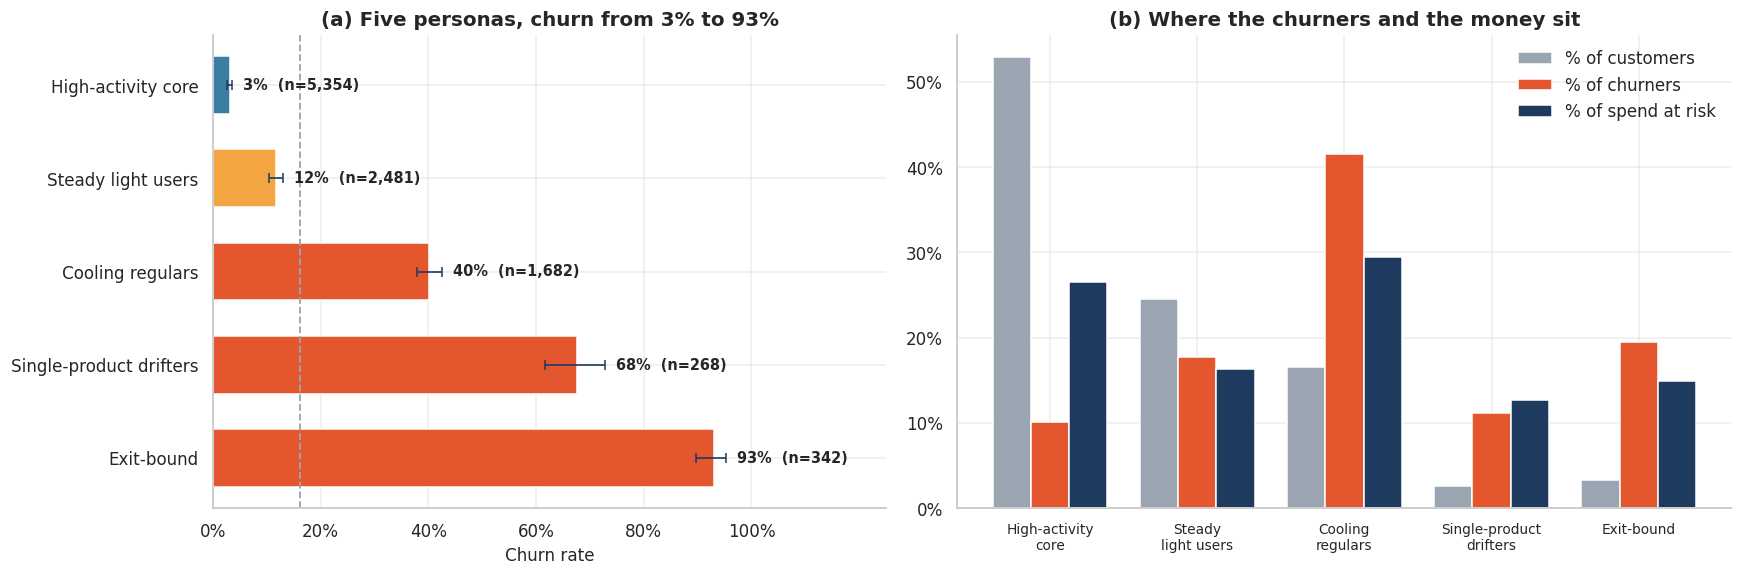

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
pe = persona.iloc[::-1]
y = np.arange(len(pe))
pcolors = [CHURNED if r >= 0.30 else (ACCENT if r >= 0.10 else RETAINED) for r in pe["churn_rate"]]
axes[0].barh(y, pe["churn_rate"], color=pcolors, height=0.62)
axes[0].errorbar(pe["churn_rate"], y, xerr=[pe["churn_rate"] - pe["ci_low"], pe["ci_high"] - pe["churn_rate"]],
                 fmt="none", ecolor=NAVY, capsize=3, lw=1.1)
for yi, (r, hi_, n) in enumerate(zip(pe["churn_rate"], pe["ci_high"], pe["customers"])):
    axes[0].text(hi_ + 0.02, yi, f"{r:.0%}  (n={n:,})", va="center", fontsize=9.5, fontweight="bold")
axes[0].axvline(BASE_RATE, color=GREY, ls="--", lw=1.2)
axes[0].set_yticks(y)
axes[0].set_yticklabels(pe.index)
pct_axis(axes[0], "x")
axes[0].set_xlim(0, 1.25)
axes[0].set_xticks(np.arange(0, 1.01, 0.2))
axes[0].set_xlabel("Churn rate")
axes[0].set_title("(a) Five personas, churn from 3% to 93%")

w = 0.26
metrics = [("share of customers", GREY), ("share of churners", CHURNED), ("share of spend at risk", NAVY)]
x = np.arange(len(persona))
for i, (m, colr) in enumerate(metrics):
    axes[1].bar(x + (i - 1) * w, persona[m], width=w, color=colr, label=m.replace("share of ", "% of "))
axes[1].set_xticks(x)
axes[1].set_xticklabels([p.replace(" ", "\n", 1) for p in persona.index], fontsize=9)
pct_axis(axes[1])
axes[1].set_title("(b) Where the churners and the money sit")
axes[1].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "13_risk_personas")

**Answer.** Five personas, with churn ranging from **3% to 93%**.

| Persona | Customers | Churn | Share of churners |
|---|---|---|---|
| High-activity core | 5,354 (52.9%) | 3.1% | 10.1% |
| Steady light users | 2,481 (24.5%) | 11.6% | 17.8% |
| **Cooling regulars** | 1,682 (16.6%) | **40.1%** | **41.5%** |
| Single-product drifters | 268 (2.6%) | 67.5% | 11.1% |
| **Exit-bound** | 342 (3.4%) | **93.0%** | 19.5% |

- The three at-risk personas are **22.6% of customers but 72.2% of churners** (1,174 of 1,627).
- **Cooling regulars** are the biggest single pool of lost customers; **Exit-bound** are the most certain.
- Churn rates are stable between the 70% training and 30% test customers (for example Exit-bound 93.7% vs 91.3%, Cooling regulars 40.5% vs 39.3%).

### A hidden segment inside the "safe" core

The High-activity core churns at only 3.1%, but it holds 26.6% of churned spend. Where do its 164 churners come from?

In [26]:
core = df[df["persona"] == "High-activity core"].copy()
core["segment"] = np.where(core["spend_decile"].isin(["D9", "D10"]), "Core: top-20% spenders", "Core: everyone else")
hv = churn_summary(core, core["segment"])
hv["spend at risk ($)"] = core.assign(s=core["Total_Trans_Amt"] * core["churn"]).groupby("segment")["s"].sum()
display(hv.round(3))
print(f"{hv.loc['Core: top-20% spenders', 'churned']} of the core's {core['churn'].sum()} churners are top-20% spenders; "
      f"their spend is {hv.loc['Core: top-20% spenders', 'spend at risk ($)'] / (df['Total_Trans_Amt'] * df['churn']).sum():.1%} "
      f"of all churned spend in the bank")

big = df[df["spend_decile"].isin(["D9", "D10"])]
prof_cols = ["Total_Trans_Ct", "Total_Trans_Amt", "Avg_Utilization_Ratio", "Credit_Limit", "Total_Revolving_Bal",
             "Contacts_Count_12_mon", "Months_Inactive_12_mon", "Total_Relationship_Count", "Total_Ct_Chng_Q4_Q1"]
prof = big.groupby("Attrition_Flag")[prof_cols].mean().T.rename(index=PRETTY)
prof["difference %"] = (prof["Attrited Customer"] / prof["Existing Customer"] - 1) * 100
print(f"\nTop-20% spenders ({len(big):,} customers, {big['churn'].mean():.1%} churn): churned vs retained")
display(prof)

,customers,churned,churn_rate,ci_low,ci_high,spend at risk ($)
segment,,,,,,
Core: everyone else,3458,2,0.001,0.000,0.002,4765
Core: top-20% spenders,1896,162,0.085,0.074,0.099,1333955


162 of the core's 164 churners are top-20% spenders; their spend is 26.5% of all churned spend in the bank

Top-20% spenders (2,024 customers, 13.0% churn): churned vs retained


Attrition_Flag,Attrited Customer,Existing Customer,difference %
12-month transactions,68.875,95.645,-27.989
12-month spend ($),"7,937.087","9,954.737",-20.268
Utilisation ratio,0.084,0.253,-66.940
Credit limit ($),"14,085.418","11,433.259",23.197
Revolving balance ($),724.213,"1,347.408",-46.251
Contacts (12 mo),2.924,2.137,36.798
Months inactive,2.646,2.244,17.922
Products held,2.973,2.570,15.716
Txn-count change Q4/Q1,0.772,0.727,6.311


**Answer.** Almost entirely from the **top-20% spenders**: **162 of the core's 164 churners** (churn 8.5% among 1,896 customers) versus **2 of 3,458** (0.1%) in the rest of the core. This one group carries **26.5% of all churned spend** in the bank.

Compared with the top spenders who stayed, these churners have **much lower utilisation (0.08 vs 0.25)**, lower revolving balances (\$724 vs \$1,347), **larger credit limits (\$14.1K vs \$11.4K)**, fewer transactions (69 vs 96) and more bank contacts (2.9 vs 2.1). The profile - affluent customers who pay in full and carry no balance - fits people who could easily shift spend to a competitor's premium card. That is a *hypothesis*; the data cannot test it. What it does show is that **activity-based personas are blind to this group**, so high-value customers need their own watch-list.

## Q10. Can a simple, explainable scorecard rank customers by churn risk - and what do we lose by excluding the "post-decision" signals?

**Method.** A **Weight-of-Evidence scorecard**, the technique banks use because every point can be explained to a regulator. Each variable is cut into bins (learned on the 70% **training** customers only); each bin gets a risk weight; a customer's score is the sum of the weights. No black-box model, no scikit-learn - just NumPy and Pandas. It is evaluated on the 30% of customers (3,039) it never saw, with:

- **AUC**: the probability that a random churner scores above a random stayer (0.5 = chance, 1.0 = perfect);
- **KS**: the largest gap between the churner and stayer score distributions;
- **top-10% precision / capture**: if we contact the 10% highest-scored customers, how many are real churners, and what share of all churners do we reach?

Four feature sets are compared: demographics only; the **core 4** behaviours; the **recommended 6** (core 4 plus utilisation and the Q4/Q1 spend ratio); and **all 10 behaviours**, including the likely post-decision signals (revolving balance, bank contacts) plus total spend and credit limit.

> **Function spotlight - `np.quantile`, `pd.cut` with infinite edges, `Series.rank`**
> `np.quantile(x, [0, .125, ...])` returns the values that split a column into equal-sized groups. Using `-inf` and `+inf` as the outer edges makes sure unseen customers always land in a bin. `rank()` converts scores to ranks, which is all the AUC calculation needs.

*Caveat: adding up weights treats variables as independent, so correlated variables are double-counted. The scores are for ranking customers, not calibrated probabilities.*

In [27]:
def fit_woe(train, feats, nbins=8):
    """Learn Weight-of-Evidence bins on TRAINING rows only. WoE = ln(share of churners / share of stayers) in a bin."""
    maps = {}
    for f in feats:
        x = train[f]
        if pd.api.types.is_numeric_dtype(x) and x.nunique() > 12:
            edges = np.unique(np.quantile(x, np.linspace(0, 1, nbins + 1)))
            edges[0], edges[-1] = -np.inf, np.inf
            grp, kind = pd.cut(x, edges, include_lowest=True), "num"
        else:
            edges, grp, kind = None, x.astype(str), "cat"
        t = pd.crosstab(grp, train["churn"]) + 0.5
        woe = np.log((t[1] / t[1].sum()) / (t[0] / t[0].sum()))
        maps[f] = {"kind": kind, "edges": edges, "woe": woe}
    return maps


def apply_woe(d, maps):
    """Replace each value by the WoE of its bin; unseen bins get 0 (= no evidence either way)."""
    out = pd.DataFrame(index=d.index)
    for f, m in maps.items():
        grp = pd.cut(d[f], m["edges"], include_lowest=True) if m["kind"] == "num" else d[f].astype(str)
        out[f] = grp.map(m["woe"]).astype(float).fillna(0.0)
    return out


CORE4 = ["Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1", "Total_Relationship_Count", "Months_Inactive_12_mon"]
RECOMMENDED = CORE4 + ["Avg_Utilization_Ratio", "Total_Amt_Chng_Q4_Q1"]
MODELS = {
    "Demographics only": ["Customer_Age", "Gender", "Income_Category", "Education_Level", "Marital_Status",
                          "Card_Category", "Dependent_count", "Months_on_book"],
    "Core 4 behaviours": CORE4,
    "Actionable 6 (recommended)": RECOMMENDED,
    "All 10 behaviours (incl. post-decision signals)": RECOMMENDED + ["Total_Trans_Amt", "Total_Revolving_Bal",
                                                                      "Contacts_Count_12_mon", "Credit_Limit"],
}

train, test = df[df["is_train"]].copy(), df[~df["is_train"]].copy()
scores, maps_all, perf = {}, {}, []
for name, feats in MODELS.items():
    maps_all[name] = fit_woe(train, feats)
    s_tr = apply_woe(train, maps_all[name]).sum(axis=1).to_numpy()      # score = sum of WoE across features
    s_te = apply_woe(test, maps_all[name]).sum(axis=1).to_numpy()
    scores[name] = s_te
    top = np.argsort(-s_te, kind="stable")[: int(0.10 * len(test))]
    perf.append({"model": name, "features": len(feats),
                 "AUC train": auc_score(train["churn"], s_tr), "AUC test": auc_score(test["churn"], s_te),
                 "KS test": ks_score(test["churn"], s_te),
                 "top-10% precision": test["churn"].to_numpy()[top].mean(),
                 "top-10% captures": test["churn"].to_numpy()[top].sum() / test["churn"].sum()})
perf = pd.DataFrame(perf).set_index("model")
display(perf.round(3))

,features,AUC train,AUC test,KS test,top-10% precision,top-10% captures
model,,,,,,
Demographics only,8,0.566,0.530,0.070,0.218,0.135
Core 4 behaviours,4,0.883,0.888,0.657,0.673,0.417
Actionable 6 (recommended),6,0.905,0.915,0.675,0.779,0.483
All 10 behaviours (incl. post-decision signals),10,0.940,0.944,0.745,0.871,0.540


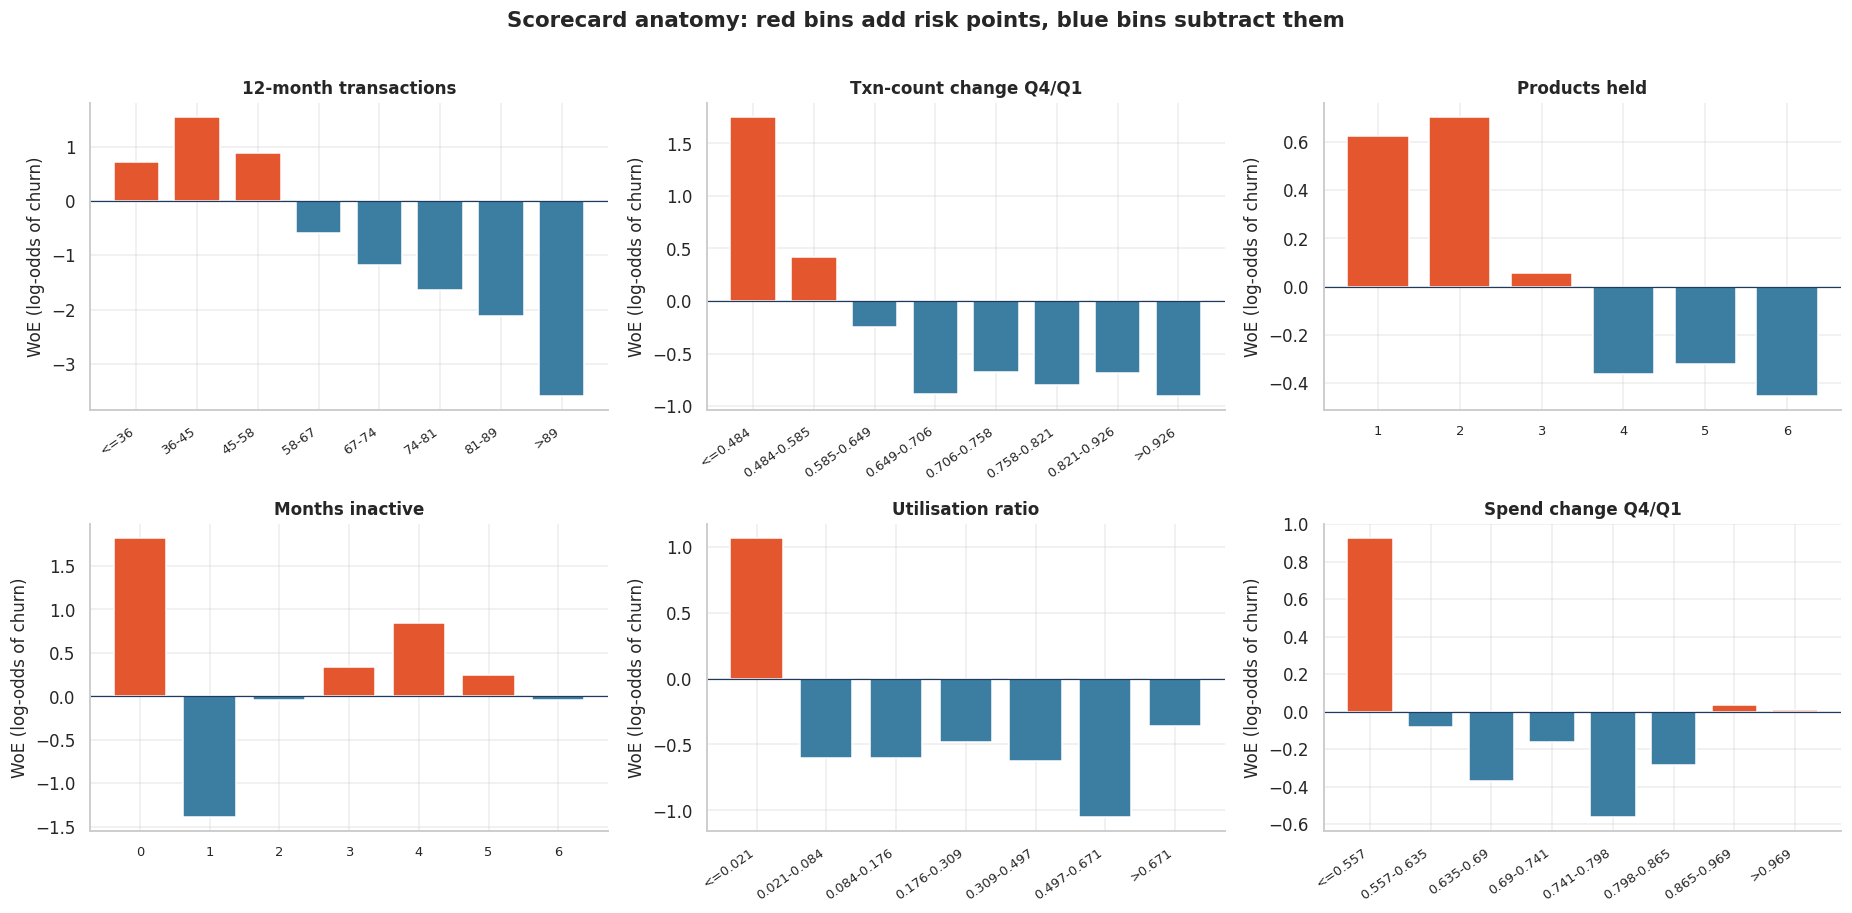

In [28]:
# ---- What does the scorecard actually look like? WoE profile of the six recommended features ----
def bin_label(iv):
    l, r = iv.left, iv.right
    if np.isinf(l):
        return f"<={r:.3g}"
    if np.isinf(r):
        return f">{l:.3g}"
    return f"{l:.3g}-{r:.3g}"

fig, axes = plt.subplots(2, 3, figsize=(17, 8.2))
for ax, f in zip(axes.ravel(), RECOMMENDED):
    m = maps_all["Actionable 6 (recommended)"][f]
    woe = m["woe"]
    labs = [bin_label(i) for i in woe.index] if m["kind"] == "num" else [str(i) for i in woe.index]
    ax.bar(range(len(woe)), woe.values, color=[CHURNED if v > 0 else RETAINED for v in woe.values], width=0.75)
    ax.axhline(0, color=NAVY, lw=0.8)
    ax.set_xticks(range(len(woe)))
    ax.set_xticklabels(labs, rotation=35 if m["kind"] == "num" else 0, ha="right" if m["kind"] == "num" else "center", fontsize=8.5)
    ax.set_title(PRETTY[f], fontsize=11)
    ax.set_ylabel("WoE (log-odds of churn)")
fig.suptitle("Scorecard anatomy: red bins add risk points, blue bins subtract them", y=1.01, fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "14_scorecard_woe_profile")

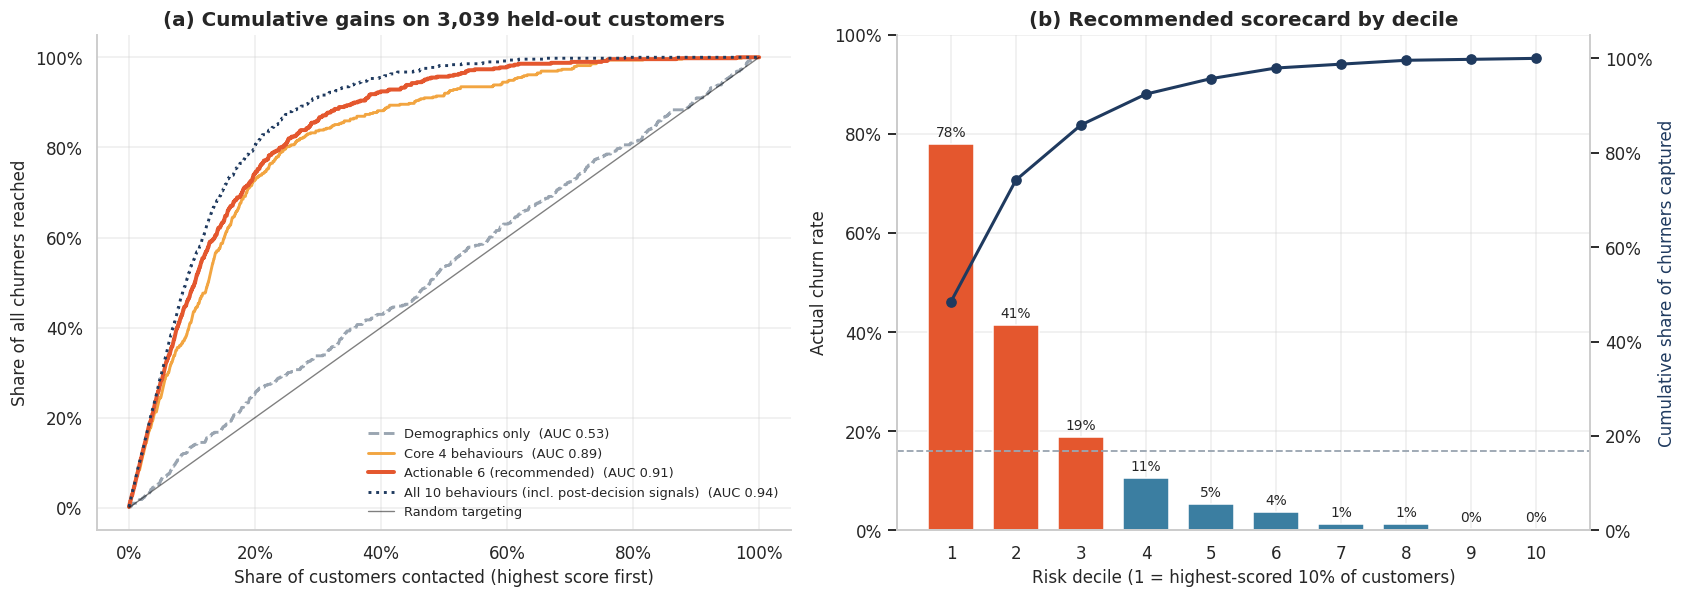

,customers,churners,churn_rate,avg_spend,cumulative capture,lift
decile,,,,,,
1,304,237,0.780,"2,084.842",0.485,4.845
2,304,126,0.414,"2,194.832",0.742,2.576
3,304,57,0.188,"2,564.556",0.859,1.165
4,304,32,0.105,"3,005.891",0.924,0.654
5,304,16,0.053,"3,662.822",0.957,0.327
6,303,11,0.036,"4,244.957",0.980,0.226
7,304,4,0.013,"4,908.283",0.988,0.082
8,304,4,0.013,"5,061.026",0.996,0.082
9,304,1,0.003,"6,761.510",0.998,0.020


In [29]:
def gains_curve(y, s):
    order = np.argsort(-np.asarray(s), kind="stable")
    yy = np.asarray(y)[order]
    return np.arange(1, len(yy) + 1) / len(yy), np.cumsum(yy) / yy.sum()

best = "Actionable 6 (recommended)"
test["score"] = scores[best]
test["decile"] = pd.qcut(test["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
dec_tab = test.groupby("decile", observed=True).agg(customers=("churn", "size"), churners=("churn", "sum"),
                                                    churn_rate=("churn", "mean"), avg_spend=("Total_Trans_Amt", "mean"))
dec_tab["cumulative capture"] = dec_tab["churners"].cumsum() / test["churn"].sum()
dec_tab["lift"] = dec_tab["churn_rate"] / test["churn"].mean()

line_styles = {"Demographics only": (GREY, "--"), "Core 4 behaviours": (ACCENT, "-"),
               best: (CHURNED, "-"), "All 10 behaviours (incl. post-decision signals)": (NAVY, ":")}
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6))
for name, (colr, ls) in line_styles.items():
    xg, yg = gains_curve(test["churn"], scores[name])
    axes[0].plot(xg, yg, color=colr, ls=ls, lw=2.6 if name == best else 1.9,
                 label=f"{name}  (AUC {perf.loc[name, 'AUC test']:.2f})")
axes[0].plot([0, 1], [0, 1], color="black", lw=0.9, alpha=0.5, label="Random targeting")
pct_axis(axes[0])
pct_axis(axes[0], "x")
axes[0].set_xlabel("Share of customers contacted (highest score first)")
axes[0].set_ylabel("Share of all churners reached")
axes[0].set_title(f"(a) Cumulative gains on {len(test):,} held-out customers")
axes[0].legend(loc="lower right", fontsize=8.5)

axes[1].bar(dec_tab.index.astype(str), dec_tab["churn_rate"], color=[CHURNED if r > BASE_RATE else RETAINED for r in dec_tab["churn_rate"]], width=0.7)
axes[1].axhline(BASE_RATE, ls="--", color=GREY, lw=1.2)
for i, r in enumerate(dec_tab["churn_rate"]):
    axes[1].text(i, r + 0.015, f"{r:.0%}", ha="center", fontsize=9)
ax2 = axes[1].twinx()
ax2.plot(dec_tab.index.astype(str), dec_tab["cumulative capture"], color=NAVY, marker="o", lw=2)
ax2.set_ylim(0, 1.05)
pct_axis(ax2)
ax2.set_ylabel("Cumulative share of churners captured", color=NAVY)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
pct_axis(axes[1])
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Risk decile (1 = highest-scored 10% of customers)")
axes[1].set_ylabel("Actual churn rate")
axes[1].set_title("(b) Recommended scorecard by decile")
fig.tight_layout()
save_fig(fig, "15_scorecard_performance")

display(dec_tab.round(3))

**Answer.** Yes - and the comparison is the interesting part.

| Feature set | AUC (test) | KS | Top-10% precision | Top-10% captures |
|---|---|---|---|---|
| Demographics only (8 fields) | 0.530 | 0.070 | 21.8% | 13.5% |
| Core 4 behaviours | 0.888 | 0.657 | 67.3% | 41.7% |
| **Recommended 6** | **0.915** | **0.675** | **77.9%** | **48.3%** |
| All 10 (incl. post-decision signals) | 0.944 | 0.745 | 87.1% | 54.0% |

- **Demographics alone are a coin flip (0.53).** Four behaviours lift the AUC to 0.89 and six reach 0.915. Training and test AUC are close (0.905 vs 0.915), so there is no sign of overfitting.
- **The top-scored 10% of customers churn at 78%** (4.8x the base rate); the top two deciles reach **74%** of all churners and the top three **86%**.
- **The cost of staying honest is small but real.** Adding revolving balance, contacts, spend and credit limit gains 0.029 AUC and 6 points of top-decile capture - but those gains come largely from signals that probably appear *after* the decision to leave (Q7). The recommended 6 give most of the benefit with signals a team could plausibly act on.
- The anatomy chart makes the scorecard transparent: for example, 36-45 transactions adds the most risk, more than 89 transactions removes the most, and a Q4/Q1 ratio under 0.48 is the riskiest bin of its variable.

## Q11. If we contact the highest-risk customers, how deep should the list go - and what save rate do we need to break even?

**Method.** Take the held-out customers ranked by the recommended scorecard, scale the results up to the full base of 10,127, and for each list depth compute precision, recall and the **break-even save rate**:

`break-even save rate = cost per contact x customers contacted / (would-be churners reached x annual value of a churner)`

**Assumptions (illustrative - replace with the bank's real numbers):** \$10 per outreach (including the expected cost of an offer); \$147 of annual revenue per would-be churner (1.5% interchange on spend + 15% yield on revolving balance); only **one year** of revenue counted, which is conservative because a retained customer keeps paying in later years. The save rate is the share of would-be churners that the outreach actually keeps - unknown until a pilot measures it, which is why it is shown as a range.

Assumptions: $10 per contact | $147 illustrative annual revenue per would-be churner | results scaled to 10,127 customers


,customers contacted,would-be churners reached,precision,recall,break-even save rate
targeting depth,,,,,
top 5%,507,450,88.8%,27.6%,7.6%
top 10%,"1,013",790,78.0%,48.5%,8.7%
top 15%,"1,520","1,033",68.0%,63.4%,10.0%
top 20%,"2,026","1,210",59.7%,74.2%,11.4%
top 30%,"3,039","1,400",46.1%,85.9%,14.7%
top 40%,"4,052","1,506",37.2%,92.4%,18.3%


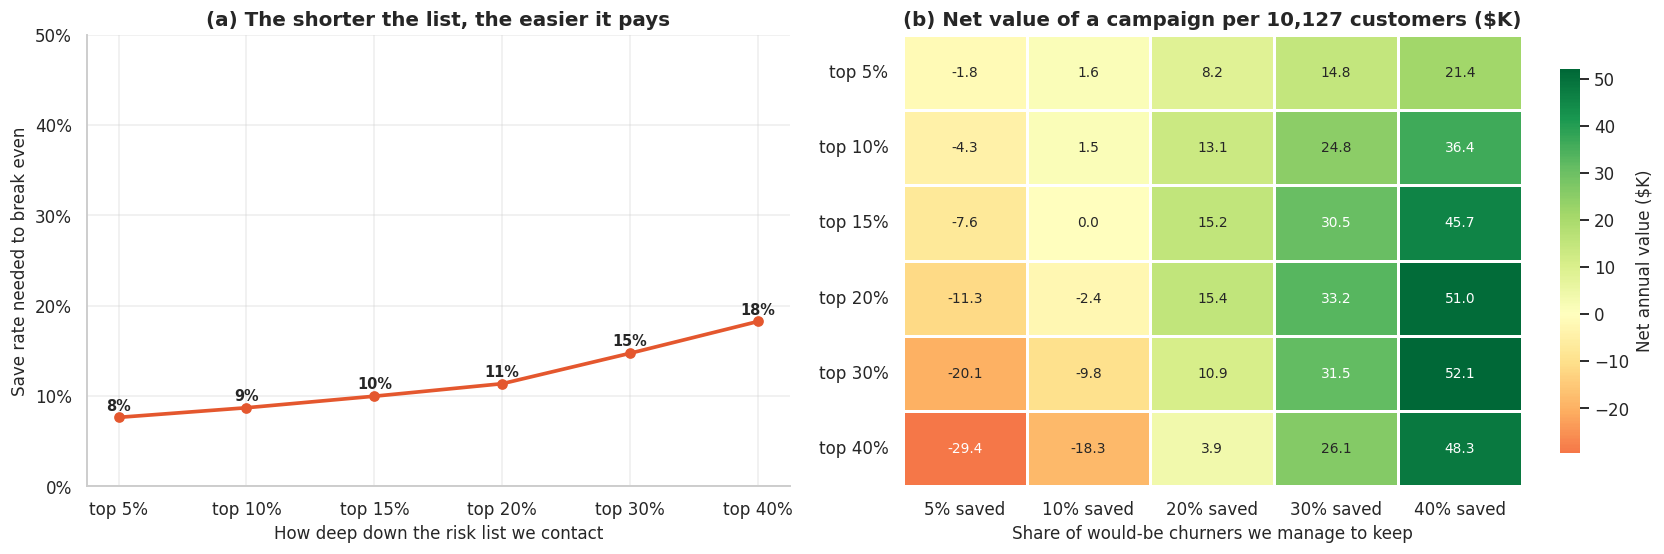

In [30]:
test_sorted = test.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
scale = len(df) / len(test_sorted)                                   # scale test results up to the full customer base
value_per_churner = df.loc[df["churn"] == 1, "rev_est"].mean()       # illustrative $ per year of a customer who would leave
depths = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
save_rates = [0.05, 0.10, 0.20, 0.30, 0.40]

rows = []
for d in depths:
    k = int(round(d * len(test_sorted)))
    top = test_sorted.iloc[:k]
    reached = top["churn"].sum() * scale
    contacted = k * scale
    rows.append({
        "targeting depth": f"top {d:.0%}", "customers contacted": contacted, "would-be churners reached": reached,
        "precision": top["churn"].mean(), "recall": top["churn"].sum() / test_sorted["churn"].sum(),
        "break-even save rate": COST_PER_CONTACT * contacted / (reached * value_per_churner),
    })
econ = pd.DataFrame(rows).set_index("targeting depth")
print(f"Assumptions: ${COST_PER_CONTACT:.0f} per contact | ${value_per_churner:,.0f} illustrative annual revenue per would-be churner "
      f"| results scaled to {len(df):,} customers")
display(econ.style.format({"customers contacted": "{:,.0f}", "would-be churners reached": "{:,.0f}", "precision": "{:.1%}",
                           "recall": "{:.1%}", "break-even save rate": "{:.1%}"}))

net = pd.DataFrame(
    {f"{s:.0%} saved": [r["would-be churners reached"] * s * value_per_churner - r["customers contacted"] * COST_PER_CONTACT
                        for r in rows] for s in save_rates}, index=econ.index)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].plot(range(len(econ)), econ["break-even save rate"], color=CHURNED, marker="o", lw=2.4)
for i, v in enumerate(econ["break-even save rate"]):
    axes[0].text(i, v + 0.008, f"{v:.0%}", ha="center", fontsize=9.5, fontweight="bold")
axes[0].set_xticks(range(len(econ)))
axes[0].set_xticklabels(econ.index)
pct_axis(axes[0])
axes[0].set_ylim(0, max(0.5, econ["break-even save rate"].max() * 1.2))
axes[0].set_xlabel("How deep down the risk list we contact")
axes[0].set_ylabel("Save rate needed to break even")
axes[0].set_title("(a) The shorter the list, the easier it pays")

sns.heatmap(net / 1000, annot=True, fmt=".1f", cmap="RdYlGn", center=0, linewidths=0.8, linecolor="white",
            cbar_kws={"label": "Net annual value ($K)", "shrink": 0.85}, ax=axes[1], annot_kws={"fontsize": 9})
axes[1].set_xlabel("Share of would-be churners we manage to keep")
axes[1].set_ylabel("")
axes[1].set_title(f"(b) Net value of a campaign per {len(df):,} customers ($K)")
axes[1].tick_params(axis="y", rotation=0)
fig.tight_layout()
save_fig(fig, "16_campaign_economics")

**Answer.** Short lists pay most easily; the sweet spot is the top 15-20%.

| Contact the top... | Customers contacted | Would-be churners reached | Precision | Share of churners reached | Break-even save rate |
|---|---|---|---|---|---|
| 5% | 507 | 450 | 88.8% | 27.6% | 7.6% |
| **10%** | 1,013 | 790 | 78.0% | 48.5% | **8.7%** |
| 15% | 1,520 | 1,033 | 68.0% | 63.4% | 10.0% |
| **20%** | 2,026 | 1,210 | 59.7% | 74.2% | **11.4%** |
| 30% | 3,039 | 1,400 | 46.1% | 85.9% | 14.7% |
| 40% | 4,052 | 1,506 | 37.2% | 92.4% | 18.3% |

- If the outreach keeps even **10%** of the would-be churners it reaches, every list up to the top 15% breaks even or better; at a **20%** save rate the net value peaks at the top 15-20% (about \$15K per 10,127 customers) and shrinks beyond that as precision falls; at a **30%** save rate the top 20% is worth about \$33K.
- Contacting the top 40% needs an 18% save rate just to break even, and loses money at 10% or less.

**So what.** Start with the top 10-20%, measure the real save rate in a randomised pilot with a hold-out group, and widen the list only if the economics hold. The dollar figures are small because the model counts one year of modest revenue per customer; the *shape* of the trade-off is the takeaway.

---
# Step 5 - Summary of inferences and conclusion

### Hypothesis scoreboard

| # | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | Demographics explain who churns | **Rejected** | IV 0.002-0.014 vs noise 0.007; demographics-only scorecard AUC 0.53 |
| H2 | Less spend means more churn, in a straight line | **Partly - non-linear** | 35-50 transactions: 45.6% churn; \$2-3K spend: 48.1%; \$3.5-4.5K: 0.4% |
| H3 | Falling activity comes before churn | **Confirmed** | Q4/Q1 ratio below 0.5: 50.9% vs 10.6%; holds 42.8% of churners |
| H4 | Newer customers churn more | **Rejected** (beyond month 13) | 14.9%-16.9% across tenure bands |
| H5 | More products make customers stickier, even allowing for activity | **Confirmed (association)** | 1-2 products 26.9% vs 4+ 11.4%; holds inside every activity tier |
| H6 | Frequent bank contact signals dissatisfaction | **Confirmed, direction unknown** | 0 contacts 1.8%, 5 contacts 33.5%, 6 contacts 100% |
| H7 | Churners are the most valuable customers | **Rejected overall; true at the top** | 16.1% of customers vs 11.3% of spend and 9.3% of revolving balances; top-20% spenders hold 41.5% of churned spend |
| H8 | Women churn more because of income | **Rejected** | Gap persists within income band and reverses above 65 transactions |

### The story in five sentences

1. Customers do not leave because of **who they are**; they leave because of **how they use the card** - and the relationship is a hump, not a slope.
2. The clearest signals are a **falling activity trend**, a **thin relationship (one or two products)** and **medium-low usage (35-50 transactions, \$2-3K a year)**.
3. Three personas - *Cooling regulars*, *Single-product drifters* and *Exit-bound* - are 22.6% of customers and **72.2% of churners**.
4. Churn costs **less** than the headcount suggests in the middle of the portfolio and **more** at the top: the top-20% spenders hold 41.5% of churned spend, and activity signals do not see them.
5. A **six-variable, fully explainable scorecard** (AUC 0.915 on unseen customers) turns this into a ranked call list whose top 10% is 78% churners.

### Recommended playbook (hypotheses to pilot, not guaranteed wins)

| Priority | Who (trigger) | Size | Suggested action | Why |
|---|---|---|---|---|
| 1 | **Exit-bound + Single-product drifters**: 65 or fewer transactions, 1-2 products | 610 customers (6.0%), 499 churners (30.7% of all) | Assisted outreach (call or relationship manager) with a product bundle or fee-waiver offer | Highest precision; the top-10% call list breaks even at a save rate of about 9% |
| 2 | **Cooling regulars**: Q4/Q1 ratio below 0.6 with 3+ products | 1,682 customers (16.6%), 675 churners (41.5% of all) | Automated, low-cost nudges triggered by the ratio: usage rewards, reactivation offers, a third-product cross-sell | The largest pool of lost customers; digital outreach keeps cost per contact low |
| 3 | **High-value leavers**: top-20% spenders with low utilisation and above-average contacts | 2,024 customers, 13.0% churn, about \$2.1M of churned spend (41.5%) | Dedicated relationship manager, premium benefits, a competitor-card review | Invisible to activity signals; each one is worth several average customers |
| 4 | **Service-friction accounts**: 4+ bank contacts or 3-4 months inactive | 1,622 customers with 4+ contacts churn at 26.4% | Analyse *why* they contact the bank; escalate at 5+ contacts (33.5%-100% churn) | Fix the cause, not just the symptom |
| 5 | **Sleepers**: 5-6 months inactive | 302 customers, 16.9% churn | Win-back campaign before they drift into the 3-4-month danger band | Dormant but not yet gone |
| 6 | **Measure properly** | - | Randomised pilot with a hold-out group; record contact *direction*; add monthly timestamps | Turns every number above from association into proven impact |

**Treat as "already lost", not as early warnings:** revolving balances of \$1-\$400 and six bank contacts (both churned 100%). Route them to a save desk.

### Limitations (read before acting on any number)

- **A snapshot, not a timeline.** There are no dates, so behaviour and attrition share the same 12 months. Some "signals" (falling activity, small residual balances, many contacts) may be *consequences* of a customer deciding to leave. A true early-warning model needs signals measured *before* the outcome window.
- **The data looks unusually clean, possibly curated or synthetic**: a 100% churn pocket, no women above \$60K, a spend band with 0.4% churn. Verify the patterns on production data before building on them.
- **No revenue column.** Revenue and campaign economics rest on stated assumptions, count one year only and are illustrative; the *shape* of the conclusions is robust, the dollar amounts are not.
- **Descriptive thresholds.** Persona cut-offs were chosen from exploration on all customers; only the scorecard (Q10) is a clean train/test evaluation, and it is a single split on a single snapshot.
- **Established customers only** (13+ months on book), and some groups are tiny (Platinum n=20; "0 months inactive" n=29) with wide confidence intervals.
- **Association is not causation.** Products held, contact counts and gender patterns need controlled tests.
- The scorecard adds weights independently, so correlated variables are double-counted; it ranks customers but is not a calibrated probability.

### Ideas for future work (other datasets from the same portfolio)

1. **Timestamped customer histories** - e.g. the *Berka Czech bank* dataset (accounts, transactions, loans, cards over years) - to test whether a fall in activity truly *precedes* account closure.
2. **Credit-risk linkage** - combine churn with delinquency using *Credit Card Approval Prediction* or *Lending Club* (roll rates, vintages): are the customers who leave also the ones who would have defaulted?
3. **Payments behaviour** - *PaySim* or the simulated *UPI* dataset to build richer usage features (frequency, time of day, merchant mix).
4. **Experiment design** - simulate the randomised pilot from Q11 to size the sample needed to measure a 10% save rate.

### Resources used

- Dataset: [Credit Card Customers, Kaggle](https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers)
- [Pandas documentation](https://pandas.pydata.org/docs/) - `groupby`, `crosstab`, `cut`, `qcut`
- [NumPy documentation](https://numpy.org/doc/) - `select`, `quantile`, random `Generator`
- [Matplotlib](https://matplotlib.org/stable/) and [Seaborn](https://seaborn.pydata.org/) documentation
- [Binomial proportion confidence interval (Wilson score)](https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval)
- [`opendatasets` on PyPI](https://pypi.org/project/opendatasets/) - download Kaggle datasets inside a notebook

---
# Step 6 - Make a submission and share your work

1. **Kaggle:** upload this notebook to Kaggle (*New Notebook -> File -> Import*), attach the *Credit Card Customers* dataset, run all cells, then *Share -> Public*.
2. **Share the public link** with the course mentor and add it here: `Kaggle notebook: <paste link>`
3. **GitHub:** this notebook, the figures in `images/`, the data dictionary and the README are already laid out as a ready-to-push repository.
4. **(Optional) Step 7 - blog post:** a ready-to-edit draft is in `docs/blog_post_draft.md`; copy the explanations and embed code cells and outputs.

*Thank you for reading.*

In [31]:
# Final housekeeping: list every figure saved for the README
for p in sorted(IMG_DIR.glob("*.png")):
    print(p.relative_to(ROOT))

images/01_class_balance_card_mix.png
images/02_distributions_by_churn.png
images/03_correlation_heatmap.png
images/04_demographics_forest_plot.png
images/05_driver_ranking_iv.png
images/06_engagement_curves.png
images/07_activity_trend.png
images/08_service_friction.png
images/09_relationship_depth.png
images/10_gender_income_check.png
images/11_balance_pockets_utilisation.png
images/12_value_at_stake.png
images/13_risk_personas.png
images/14_scorecard_woe_profile.png
images/15_scorecard_performance.png
images/16_campaign_economics.png
